# Deepfake detection v2: a matched 2x2 ablation (Kaggle)

Follow-up to the course project (MobileNetV2 + feature gate + FFT frequency branch on FaceForensics++ C23).
The model idea is unchanged. What changes is how it is trained and measured, so every number can be defended.

**What this notebook does**

1. Builds an **identity-disjoint** train/val/test split: no person or source video appears in two splits.
2. Trains four variants under **one identical protocol**, with several seeds each.
3. Writes a report with confidence intervals, per-manipulation results, and a plain statement of what the data does and does not support.

**Before you run it**

1. **Accelerator:** Settings (right panel) > Accelerator > **GPU T4 x2**. Choose T4 rather than P100: the P100 is an older GPU and may not work with the current PyTorch build.
2. **Internet:** Settings > Internet > **On**. It is needed once, to download the ImageNet weights for MobileNetV2.
3. **Dataset:** **+ Add Input** > search `faceforensics-c23-extracted-faces-100k` (gradientvoyager) > add it. The notebook reads it in place, so nothing is downloaded.

Then run the cells top to bottom. Run the quick test before the experiment.

_Generated from the `deepfake_v2/` package by `build_notebook.py`. To change the code, edit the package and rebuild._

## The idea in short

**Question.** Do two additions to a MobileNetV2 detector help: a learned *feature gate* and an *FFT frequency branch*? Alone, or together?

| Variant | Feature gate | FFT branch |
|---|:---:|:---:|
| `base` | no | no |
| `attn` | yes | no |
| `freq` | no | yes |
| `hybrid` | yes | yes |

**Why "matched".** In the original notebooks the three models were trained on different amounts of data, for different numbers of epochs, with different losses. A gain could not be blamed on the component. Here only the component changes: same data, epochs, loss, scheduler and dense head.

**Why the metrics changed.** About 83% of test frames are fake, so always answering "fake" already scores that much. The report puts accuracy next to that baseline and adds metrics that ignore the class split: AUC, balanced accuracy, equal error rate. It also decides per video and puts 95% intervals around results by resampling test *videos*, because frames from one video are nearly copies of each other.

**What the FFT branch is.** It converts each face to grayscale, takes the 2-D Fourier transform, and feeds the log-magnitude spectrum to a small CNN. The hope is that manipulation leaves traces in the frequency content. In this design the branch ends with global average pooling, which throws away *which* frequencies matter, and it reads 224x224 JPEG crops after resizing and augmentation. A null result for the FFT branch here therefore says this design does not help, not that frequency cues are useless.

**Leakage, in one line.** In the Kaggle split a fake video `A_B` is placed by one of its two ids, so the other id often appears in training. The clean split puts every original video and actor in exactly one split.

## Settings

Constants you can change, plus two checks: the GPU and internet access.

In [1]:
import os
import socket
import subprocess
import sys

import torch

def run(*args):
    '''Run `python <args>` with this notebook's own interpreter, show its output, and stop the cell if it fails.

    Shell lines such as `!python ...` hide failures, so every step goes through this function.
    '''
    proc = subprocess.Popen([sys.executable, *args], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in proc.stdout:
        print(line, end="")
    if proc.wait() != 0:
        raise RuntimeError(f"failed with exit code {proc.returncode}: python {' '.join(args)}")

os.chdir("/kaggle/working")          # outputs and the dfv2 package go here
os.makedirs("dfv2", exist_ok=True)   # the module cells below write into this folder

OUT_DIR = "/kaggle/working/runs"     # kept as this notebook's output
SEEDS = [0, 1, 2]                          # [0] first (4 runs); [0, 1, 2] for the full study
EPOCHS = 5
SPLIT = "clean"                      # identity-disjoint; "original" is Kaggle's assignment (use another OUT_DIR)
EXTRA_FLAGS = ""                     # e.g. "--no-amp" if mixed precision errors in the quick test

print("torch", torch.__version__, "| cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU. Settings > Accelerator > GPU T4 x2. On CPU this would take days.")

try:
    socket.create_connection(("download.pytorch.org", 443), timeout=10).close()
    print("internet: ok")
except OSError:
    print("internet: NOT reachable. Settings > Internet > On, then re-run this cell.")

torch 2.11.0+cu128 | cuda available: True
GPU: Tesla T4
internet: ok


## The code

Each cell below writes one file of the `dfv2` package into the working folder. Running them defines everything the later cells use, and you can read or change any of them. These are the files the project's automated tests run against.

### `dfv2/__init__.py`

Marks `dfv2` as a Python package.

In [2]:
%%writefile dfv2/__init__.py
"""Evaluation harness and matched 2x2 ablation for the hybrid deepfake detector."""

Writing dfv2/__init__.py


### `dfv2/metrics.py`

Every metric, written to accept per-row weights so the bootstrap can resample whole videos. Convention throughout: label 1 = fake, and a score is P(fake).

In [3]:
%%writefile dfv2/metrics.py
"""Evaluation metrics for binary real/fake detection.

Convention everywhere: label 1 = fake (the positive class), label 0 = real,
and a score is P(fake). Every metric accepts optional per-row weights `w`. The
cluster bootstrap uses that to resample whole videos: a video drawn k times gets
weight k on each of its frames, so no rows are copied.
"""
from __future__ import annotations

from typing import Callable

import numpy as np


def _weights(n: int, w) -> np.ndarray:
    return np.ones(n) if w is None else np.asarray(w, dtype=float)


def _ranking_inputs(y, score, w):
    """Cast inputs and drop zero-weight rows (they cannot change a ranking metric)."""
    y = np.asarray(y).astype(int)
    score = np.asarray(score, dtype=float)
    w = _weights(len(y), w)
    keep = w > 0
    return y[keep], score[keep], w[keep]


def _has_both_classes(y: np.ndarray, w: np.ndarray) -> bool:
    return w[y == 1].sum() > 0 and w[y == 0].sum() > 0


# --- threshold metrics -------------------------------------------------------

def predict(score, threshold: float = 0.5) -> np.ndarray:
    return (np.asarray(score) >= threshold).astype(int)


def confusion_counts(y, pred, w=None) -> tuple[float, float, float, float]:
    """Return (tn, fp, fn, tp) as floats."""
    y = np.asarray(y).astype(int)
    pred = np.asarray(pred).astype(int)
    w = _weights(len(y), w)
    tn = w[(y == 0) & (pred == 0)].sum()
    fp = w[(y == 0) & (pred == 1)].sum()
    fn = w[(y == 1) & (pred == 0)].sum()
    tp = w[(y == 1) & (pred == 1)].sum()
    return float(tn), float(fp), float(fn), float(tp)


def _ratio(num: float, den: float) -> float:
    return num / den if den > 0 else float("nan")


def accuracy(y, pred, w=None) -> float:
    tn, fp, fn, tp = confusion_counts(y, pred, w)
    return _ratio(tn + tp, tn + fp + fn + tp)


def balanced_accuracy(y, pred, w=None) -> float:
    """Mean of recall on fakes (TPR) and recall on reals (TNR); insensitive to prevalence."""
    tn, fp, fn, tp = confusion_counts(y, pred, w)
    return (_ratio(tp, tp + fn) + _ratio(tn, tn + fp)) / 2


def fake_recall(y, pred, w=None) -> float:
    tn, fp, fn, tp = confusion_counts(y, pred, w)
    return _ratio(tp, tp + fn)


def real_recall(y, pred, w=None) -> float:
    tn, fp, fn, tp = confusion_counts(y, pred, w)
    return _ratio(tn, tn + fp)


def real_precision(y, pred, w=None) -> float:
    """Of the faces called real, the share that are real. Depends on prevalence."""
    tn, fp, fn, tp = confusion_counts(y, pred, w)
    return _ratio(tn, tn + fn)


def majority_baseline(y, w=None) -> float:
    """Accuracy of always predicting the more common class."""
    y = np.asarray(y).astype(int)
    w = _weights(len(y), w)
    pos, neg = w[y == 1].sum(), w[y == 0].sum()
    return _ratio(max(pos, neg), pos + neg)


# --- ranking metrics ---------------------------------------------------------

def roc_points(y, score, w=None) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """ROC polygon with exact tie handling: (fpr, tpr, thresholds).

    A face is called fake when score >= threshold. The first point is (0, 0) at an
    infinite threshold. Raises ValueError if one class is missing.
    """
    y, score, w = _ranking_inputs(y, score, w)
    if not _has_both_classes(y, w):
        raise ValueError("ROC needs both classes")
    uniq, inverse = np.unique(score, return_inverse=True)
    pos = np.bincount(inverse, weights=w * (y == 1), minlength=len(uniq))
    neg = np.bincount(inverse, weights=w * (y == 0), minlength=len(uniq))
    tpr = np.concatenate([[0.0], np.cumsum(pos[::-1]) / pos.sum()])
    fpr = np.concatenate([[0.0], np.cumsum(neg[::-1]) / neg.sum()])
    thresholds = np.concatenate([[np.inf], uniq[::-1]])
    return fpr, tpr, thresholds


def auc_roc(y, score, w=None) -> float:
    try:
        fpr, tpr, _ = roc_points(y, score, w)
    except ValueError:
        return float("nan")
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))


def _eer_crossing(fpr: np.ndarray, tpr: np.ndarray) -> tuple[int, float]:
    """First ROC point at or past the line fpr = 1 - tpr, and the interpolated EER."""
    d = fpr + tpr - 1.0  # starts at -1, ends at +1, never decreases
    i = int(np.argmax(d >= 0))
    t = -d[i - 1] / (d[i] - d[i - 1])
    return i, float(fpr[i - 1] + t * (fpr[i] - fpr[i - 1]))


def equal_error_rate(y, score, w=None) -> float:
    """Error rate at the operating point where false-accept rate equals false-reject rate."""
    try:
        fpr, tpr, _ = roc_points(y, score, w)
    except ValueError:
        return float("nan")
    return _eer_crossing(fpr, tpr)[1]


def eer_threshold(y, score, w=None) -> float:
    """Score threshold at the equal-error point. Choose it on validation data, never on test."""
    fpr, tpr, thresholds = roc_points(y, score, w)
    return float(thresholds[_eer_crossing(fpr, tpr)[0]])


def tpr_at_fpr(y, score, fpr_target: float, w=None) -> float:
    """Share of fakes caught while flagging at most `fpr_target` of real faces."""
    try:
        fpr, tpr, _ = roc_points(y, score, w)
    except ValueError:
        return float("nan")
    return float(tpr[np.searchsorted(fpr, fpr_target, side="right") - 1])


# --- grouping ----------------------------------------------------------------

def aggregate_by_group(groups, y, score) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Collapse frames to one row per group (video): mean score, shared label.

    Returns (group_ids sorted, labels, mean_scores).
    """
    ids, codes = np.unique(np.asarray(groups), return_inverse=True)
    counts = np.bincount(codes)
    label_sum = np.bincount(codes, weights=np.asarray(y, dtype=float))
    if not np.all((label_sum == 0) | (label_sum == counts)):
        raise ValueError("labels differ within a group")
    mean_score = np.bincount(codes, weights=np.asarray(score, dtype=float)) / counts
    return ids, (label_sum > 0).astype(int), mean_score


def per_group_auc(y, score, groups, negative_group: str = "Real", w=None) -> dict[str, float]:
    """AUC of each non-negative group against every row of the negative group."""
    y = np.asarray(y)
    score = np.asarray(score)
    groups = np.asarray(groups)
    w = None if w is None else np.asarray(w)
    out = {}
    for g in np.unique(groups):
        if g == negative_group:
            continue
        m = (groups == g) | (groups == negative_group)
        out[str(g)] = auc_roc(y[m], score[m], None if w is None else w[m])
    return out


def per_group_accuracy(y, pred, groups, w=None) -> dict[str, float]:
    """Accuracy inside each group. For the real group this is recall on reals."""
    y = np.asarray(y)
    pred = np.asarray(pred)
    groups = np.asarray(groups)
    w = _weights(len(y), w)
    out = {}
    for g in np.unique(groups):
        m = groups == g
        out[str(g)] = _ratio(w[m & (y == pred)].sum(), w[m].sum())
    return out


# --- cluster bootstrap -------------------------------------------------------

def bootstrap_clusters(
    n_clusters: int,
    stat_fn: Callable[[np.ndarray], object],
    n_boot: int = 1000,
    seed: int = 0,
    strata: np.ndarray | None = None,
) -> tuple[np.ndarray, np.ndarray]:
    """Resample clusters (videos) with replacement and evaluate `stat_fn` on each draw.

    `stat_fn(counts)` receives how many times each cluster was drawn (length
    `n_clusters`) and returns a scalar or 1-D array. With `strata`, clusters are
    resampled within their stratum, which keeps the real/fake video counts fixed.
    Returns (point_estimate, samples) with shapes (k,) and (n_boot, k).
    """
    rng = np.random.default_rng(seed)
    point = np.atleast_1d(np.asarray(stat_fn(np.ones(n_clusters)), dtype=float))
    groups = [np.arange(n_clusters)] if strata is None else [
        np.flatnonzero(strata == s) for s in np.unique(strata)
    ]
    samples = np.empty((n_boot, point.size))
    for b in range(n_boot):
        counts = np.zeros(n_clusters)
        for idx in groups:
            counts[idx] = rng.multinomial(len(idx), np.full(len(idx), 1.0 / len(idx)))
        samples[b] = stat_fn(counts)
    return point, samples


def percentile_ci(samples: np.ndarray, alpha: float = 0.05) -> tuple[np.ndarray, np.ndarray]:
    lo, hi = np.nanpercentile(samples, [100 * alpha / 2, 100 * (1 - alpha / 2)], axis=0)
    return np.atleast_1d(lo), np.atleast_1d(hi)

Writing dfv2/metrics.py


### `dfv2/splits.py`

The identity-disjoint split and the leakage audit. Original videos and actors are nodes, each fake video links its two ids, and linked groups are never separated.

In [4]:
%%writefile dfv2/splits.py
"""Identity-disjoint re-split of the FaceForensics++ frames, plus an audit of any split.

Why: in the Kaggle manifest a fake video "A_B" is put in a split by one of its two ids, so the
other id often also appears in training. A model can then see a person's face (or the video it was
pasted into) in training and meet the same identity again at test time.

How: every original video id (and every DeepFakeDetection actor) is a node, and each fake video
links its two ids. All frames whose videos are connected must live in the same split, so splitting
is done per connected component. Frame counts decide how components are dealt out to train, val and
test; the seed only changes which components land where.

No torch and no import from manifest.py (manifest.py imports this module).
"""
from __future__ import annotations

import re

import numpy as np
import pandas as pd

SPLIT_NAMES = ("train", "val", "test")
TARGET_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15}
DEFAULT_DROP_TYPES = ("DeepFakeDetection",)
BALANCE_TOLERANCE = 0.03       # max gap between a split's frame share and its target
BIG_COMPONENT_SHARE = 0.02     # components above this share of all frames are placed first
_DFD_ACTORS = re.compile(r"^(\d+)_(\d+)__")


def video_identities(video: str) -> tuple[str, ...]:
    """Identity nodes behind a video key ("Type/stem"): one for a real video, two for a fake."""
    fake_type, stem = video.split("/", 1)
    if fake_type == "Real":
        return (f"yt:{stem}",)
    if fake_type == "DeepFakeDetection":
        match = _DFD_ACTORS.match(stem)
        if not match:
            raise ValueError(f"unexpected DeepFakeDetection video name {video!r}")
        return tuple(f"actor:{g}" for g in match.groups())
    parts = stem.split("_")
    if len(parts) != 2:
        raise ValueError(f"unexpected video name {video!r}")
    return (f"yt:{parts[0]}", f"yt:{parts[1]}")


def _components(videos) -> dict[str, int]:
    """Map each video to the index of its connected component of linked identities."""
    parent: dict[str, str] = {}

    def find(x: str) -> str:
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    ids_of = {v: video_identities(v) for v in videos}
    for ids in ids_of.values():
        for other in ids[1:]:
            parent[find(other)] = find(ids[0])
        find(ids[0])
    members: dict[str, set[str]] = {}
    for ids in ids_of.values():
        members.setdefault(find(ids[0]), set()).update(ids)
    # Name each component by its smallest identity so numbering does not depend on row order.
    order = sorted(members, key=lambda root: min(members[root]))
    index = {root: i for i, root in enumerate(order)}
    return {v: index[find(ids[0])] for v, ids in ids_of.items()}


def _assign(frames: pd.Series, fractions: dict[str, float], seed: int) -> dict[int, str]:
    """Deal components to splits, always to the split furthest below its target share."""
    rng = np.random.default_rng(seed)
    total = float(frames.sum())
    comps = np.sort(frames.index.to_numpy())
    rng.shuffle(comps)
    big = sorted((c for c in comps if frames[c] > BIG_COMPONENT_SHARE * total), key=lambda c: -frames[c])
    rest = [c for c in comps if frames[c] <= BIG_COMPONENT_SHARE * total]
    target = {s: f * total for s, f in fractions.items()}
    filled = dict.fromkeys(fractions, 0.0)
    out: dict[int, str] = {}
    for c in big + rest:
        s = max(fractions, key=lambda k: (target[k] - filled[k]) / target[k])
        out[int(c)] = s
        filled[s] += float(frames[c])
    return out


def _check_result(df: pd.DataFrame, fractions: dict[str, float]) -> None:
    share = df["split"].value_counts(normalize=True)
    for name, target in fractions.items():
        got = float(share.get(name, 0.0))
        if abs(got - target) > BALANCE_TOLERANCE:
            raise ValueError(
                f"identity graph cannot be split into {fractions}: split {name!r} would hold "
                f"{got:.1%} of frames (target {target:.0%}); a few large linked groups dominate")
        if df.loc[df["split"] == name, "label"].nunique() < 2:
            raise ValueError(f"identity graph cannot be split: split {name!r} would lack real or fake frames")


def clean_split(
    df: pd.DataFrame,
    fractions: dict[str, float] | None = None,
    seed: int = 0,
    drop_types: tuple[str, ...] = DEFAULT_DROP_TYPES,
) -> pd.DataFrame:
    """Return `df` with `split` reassigned so that no identity appears in two splits.

    Frames of `drop_types` are removed first. DeepFakeDetection is dropped by default: it has fake
    frames but no real frames from its own domain, and its actors form three linked groups (one of
    18 actors) that cannot be dealt into three balanced splits without a very uneven result.
    Rows keep their `path`, so image files stay where they are.
    """
    fractions = dict(TARGET_FRACTIONS if fractions is None else fractions)
    out = df[~df["fake_type"].isin(drop_types)].copy()
    component = _components(out["video"].unique())
    out["_component"] = out["video"].map(component)
    assignment = _assign(out.groupby("_component").size(), fractions, seed)
    out["split"] = out["_component"].map(assignment)
    _check_result(out, fractions)
    return out.drop(columns="_component").reset_index(drop=True)


def audit_identities(df: pd.DataFrame) -> dict:
    """Count how many identities appear in more than one split. All zeros means no leakage."""
    seen = df[["split", "video"]].drop_duplicates()
    ids: dict[str, set[str]] = {s: set() for s in SPLIT_NAMES}
    for split, video in zip(seen["split"], seen["video"]):
        ids[split].update(video_identities(video))
    frames = df["split"].value_counts()
    videos = seen["split"].value_counts()
    fake_share = df.groupby("split")["label"].mean()
    return {
        "frames": {s: int(frames.get(s, 0)) for s in SPLIT_NAMES},
        "videos": {s: int(videos.get(s, 0)) for s in SPLIT_NAMES},
        "identities": {s: len(ids[s]) for s in SPLIT_NAMES},
        "fake_share": {s: float(fake_share.get(s, float("nan"))) for s in SPLIT_NAMES},
        "shared": {
            "train/val": len(ids["train"] & ids["val"]),
            "train/test": len(ids["train"] & ids["test"]),
            "val/test": len(ids["val"] & ids["test"]),
        },
        "test_identities_seen_in_train": len(ids["test"] & ids["train"]),
        "test_identities": len(ids["test"]),
    }


def format_audit(audit: dict, title: str) -> str:
    lines = [title, f"  {'split':<6}{'frames':>10}{'videos':>9}{'identities':>12}{'fake share':>12}"]
    for s in SPLIT_NAMES:
        lines.append(f"  {s:<6}{audit['frames'][s]:>10,}{audit['videos'][s]:>9,}"
                     f"{audit['identities'][s]:>12,}{audit['fake_share'][s]:>12.1%}")
    shared = ", ".join(f"{k} {v}" for k, v in audit["shared"].items())
    lines.append(f"  identities in more than one split: {shared}")
    lines.append(f"  test identities also present in train: {audit['test_identities_seen_in_train']} "
                 f"of {audit['test_identities']}")
    return "\n".join(lines)

Writing dfv2/splits.py


### `dfv2/manifest.py`

Reads `dataset_manifest.csv`, or the folder layout when there is no CSV. Works out which video each frame came from, applies the split scheme, finds the dataset folder under `/kaggle/input`, and draws a fresh balanced real/fake subset each epoch.

In [5]:
%%writefile dfv2/manifest.py
"""Read dataset_manifest.csv and derive the video id that every frame belongs to.

No torch here, so reporting and tests can import this anywhere.
"""
from __future__ import annotations

import re
from pathlib import Path

import numpy as np
import pandas as pd

from .splits import DEFAULT_DROP_TYPES, clean_split

FRAME_SUFFIX = re.compile(r"_f\d+$")
SPLITS = ("train", "val", "test")


def video_key(fake_type: str, filename: str) -> str:
    """Unique id of the video a frame came from.

    The manipulation type is part of the key: the pair "636_578" exists once per
    manipulation method, and those are different videos with different artifacts.
    """
    stem = filename.rsplit(".", 1)[0]
    return f"{fake_type}/{FRAME_SUFFIX.sub('', stem)}"


IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png"}


def scan_frames(data_dir: str | Path) -> pd.DataFrame:
    """Frame table from the folder layout <data_dir>/<split>/<fake_type>/<image>.

    Used when the dataset has no manifest CSV. For the local copy it gives the same rows as the CSV,
    so the rest of the pipeline cannot tell the two routes apart.
    """
    data_dir = Path(data_dir)
    rows = []
    for split in SPLITS:
        split_dir = data_dir / split
        if not split_dir.is_dir():
            raise FileNotFoundError(f"expected folder {split_dir}")
        for type_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
            for image in sorted(type_dir.iterdir()):
                if image.suffix.lower() in IMAGE_SUFFIXES:
                    rows.append((image.name, split, type_dir.name))
    if not rows:
        raise FileNotFoundError(f"no images under {data_dir}/<train|val|test>/<type>/")
    return pd.DataFrame(rows, columns=["filename", "split", "fake_type"])


def find_data_dir(search_root: str | Path) -> Path:
    """Return the folder under `search_root` that holds train/, val/ and test/ with a Real/ class folder.

    On Kaggle an attached dataset appears under /kaggle/input/<dataset-name>/ and the depth can
    vary, so this searches rather than hard-coding a path.
    """
    root = Path(search_root)
    for real_dir in sorted(root.glob("**/train/Real")):
        base = real_dir.parent.parent
        if all((base / s).is_dir() for s in SPLITS):
            return base
    raise FileNotFoundError(
        f"no train/, val/ and test/ folders with a Real/ class folder under {root}. "
        "On Kaggle, add the dataset with '+ Add Input' first.")


def subsample_videos(df: pd.DataFrame, max_videos: int, seed: int = 0) -> pd.DataFrame:
    """Keep at most `max_videos` videos per (split, label), with every frame of each."""
    rng = np.random.default_rng(seed)
    keep: list[str] = []
    for (_split, _label), group in df.groupby(["split", "label"], sort=True):
        videos = np.sort(group["video"].unique())
        take = min(max_videos, len(videos))
        keep.extend(rng.choice(videos, size=take, replace=False))
    return df[df["video"].isin(set(keep))].reset_index(drop=True)


def load_manifest(
    data_dir: str | Path,
    max_videos: int | None = None,
    seed: int = 0,
    split: str = "original",
    split_seed: int = 0,
    drop_types: tuple[str, ...] = DEFAULT_DROP_TYPES,
) -> pd.DataFrame:
    """Return one row per frame: filename, split, fake_type, label (0 real, 1 fake), video, path.

    `split="original"` keeps the Kaggle assignment. `split="clean"` reassigns frames so that no
    identity appears in two splits (see splits.py); `drop_types` are removed in that case. Image
    paths always point at the original folders, so no file has to move.

    `max_videos` keeps a small subset of videos per (split, label). It exists for
    quick smoke runs, not for real experiments.
    """
    if split not in ("original", "clean"):
        raise ValueError(f"unknown split scheme {split!r}; use 'original' or 'clean'")
    data_dir = Path(data_dir)
    csv_path = data_dir / "dataset_manifest.csv"
    if csv_path.exists():
        df = pd.read_csv(csv_path)
        expected = np.where(df["fake_type"] == "Real", "REAL", "FAKE")
        if (df["label"].to_numpy() != expected).any():
            raise ValueError("manifest label column disagrees with fake_type")
    else:
        df = scan_frames(data_dir)
    df["label"] = (df["fake_type"] != "Real").astype(int)
    df["video"] = [video_key(t, f) for t, f in zip(df["fake_type"], df["filename"])]
    df["path"] = [str(data_dir / s / t / f) for s, t, f in zip(df["split"], df["fake_type"], df["filename"])]
    df = df[["filename", "split", "fake_type", "label", "video", "path"]]
    if split == "clean":
        df = clean_split(df, seed=split_seed, drop_types=drop_types)
    if max_videos is not None:
        df = subsample_videos(df, max_videos, seed)
    return df


def split_frame(df: pd.DataFrame, split: str) -> pd.DataFrame:
    """Rows of one split in a stable order (sorted by filename and type)."""
    out = df[df["split"] == split].sort_values(["fake_type", "filename"])
    return out.reset_index(drop=True)


def balanced_epoch_indices(labels: np.ndarray, epoch: int, seed: int) -> np.ndarray:
    """Indices for one balanced epoch: every row of the smaller class plus an equal
    number drawn without replacement from the larger class, shuffled.

    The draw depends only on (seed, epoch), so a run is reproducible, and different
    epochs see different fakes instead of discarding most of them for good.
    """
    labels = np.asarray(labels)
    rng = np.random.default_rng([seed, epoch])
    real = np.flatnonzero(labels == 0)
    fake = np.flatnonzero(labels == 1)
    small, large = (real, fake) if len(real) <= len(fake) else (fake, real)
    drawn = rng.choice(large, size=len(small), replace=False)
    return rng.permutation(np.concatenate([small, drawn]))

Writing dfv2/manifest.py


### `dfv2/models.py`

One model class for all four variants (feature gate off/on x FFT branch off/on). The FFT computation matches the original notebook exactly.

In [6]:
%%writefile dfv2/models.py
"""One model class for the 2x2 ablation: {feature gate off/on} x {FFT branch off/on}.

All four variants share the same backbone, the same dense head (only its input width
differs) and the same frequency branch design as the original notebook, so the only
thing that changes between runs is the component under test.
"""
from __future__ import annotations

import contextlib

import torch
import torch.nn as nn
from torchvision import models

# variant name -> (feature gate, frequency branch)
VARIANTS: dict[str, tuple[bool, bool]] = {
    "base": (False, False),
    "attn": (True, False),
    "freq": (False, True),
    "hybrid": (True, True),
}

BACKBONE_CHANNELS = 1280
FREQ_CHANNELS = 64


def _no_autocast(x: torch.Tensor):
    """cuFFT needs float32 for 224x224 inputs, so keep the FFT out of mixed precision."""
    return torch.autocast("cuda", enabled=False) if x.is_cuda else contextlib.nullcontext()


def frequency_map(x: torch.Tensor) -> torch.Tensor:
    """(B, 3, H, W) normalised RGB -> (B, 1, H, W) log-magnitude FFT scaled to [0, 1] per image.

    Matches the original notebook exactly: channel mean, 2-D FFT, fftshift, log1p of the
    magnitude, per-image min-max scaling. It is computed from the augmented, ImageNet-
    normalised tensor, as before, so this ablation tests the original design.
    """
    with _no_autocast(x):
        gray = x.float().mean(dim=1)
        spectrum = torch.fft.fftshift(torch.fft.fft2(gray), dim=(-2, -1))
        magnitude = torch.log1p(torch.abs(spectrum))
        lo = magnitude.amin(dim=(-2, -1), keepdim=True)
        hi = magnitude.amax(dim=(-2, -1), keepdim=True)
        return ((magnitude - lo) / (hi - lo + 1e-8)).unsqueeze(1)


class DeepfakeNet(nn.Module):
    def __init__(self, gate: bool, frequency: bool, pretrained: bool = True):
        super().__init__()
        weights = models.MobileNet_V2_Weights.DEFAULT if pretrained else None
        self.features = models.mobilenet_v2(weights=weights).features
        # A learned per-channel, per-position sigmoid gate (1x1 conv over all 1280 channels).
        # This is not squeeze-and-excitation channel attention.
        self.gate = nn.Sequential(nn.Conv2d(BACKBONE_CHANNELS, BACKBONE_CHANNELS, 1), nn.Sigmoid()) if gate else None
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.freq_branch = (
            nn.Sequential(
                nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
                nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
                nn.Conv2d(32, FREQ_CHANNELS, 3, padding=1), nn.BatchNorm2d(FREQ_CHANNELS), nn.ReLU(),
                nn.AdaptiveAvgPool2d(1),
            )
            if frequency
            else None
        )
        in_dim = BACKBONE_CHANNELS + (FREQ_CHANNELS if frequency else 0)
        self.head = nn.Sequential(
            nn.Linear(in_dim, 256), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(256, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, 2),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        feats = self.features(x)
        if self.gate is not None:
            feats = feats * self.gate(feats)
        parts = [torch.flatten(self.pool(feats), 1)]
        if self.freq_branch is not None:
            parts.append(torch.flatten(self.freq_branch(frequency_map(x)), 1))
        return self.head(torch.cat(parts, dim=1))


def build_model(variant: str, pretrained: bool = True) -> DeepfakeNet:
    if variant not in VARIANTS:
        raise ValueError(f"unknown variant {variant!r}; choose from {sorted(VARIANTS)}")
    gate, frequency = VARIANTS[variant]
    return DeepfakeNet(gate=gate, frequency=frequency, pretrained=pretrained)

Writing dfv2/models.py


### `dfv2/dataset.py`

Torch dataset, the original augmentations, and the per-epoch balanced sampler.

In [7]:
%%writefile dfv2/dataset.py
"""Torch dataset, transforms and the per-epoch balanced sampler."""
from __future__ import annotations

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, Sampler
from torchvision import transforms

from .manifest import balanced_epoch_indices

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
IMAGE_SIZE = 224


def build_transform(train: bool) -> transforms.Compose:
    """Same transforms as the original notebooks: light augmentation for training only."""
    steps: list = [transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))]
    if train:
        steps += [
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(10),
            transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        ]
    steps += [transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
    return transforms.Compose(steps)


class FrameDataset(Dataset):
    """Rows of a manifest frame -> (normalised image tensor, label). Order follows the frame."""

    def __init__(self, df: pd.DataFrame, train: bool):
        self.paths = df["path"].tolist()
        self.labels = df["label"].to_numpy()
        self.transform = build_transform(train)

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, i: int) -> tuple[torch.Tensor, int]:
        with Image.open(self.paths[i]) as image:
            return self.transform(image.convert("RGB")), int(self.labels[i])


class BalancedEpochSampler(Sampler[int]):
    """Yields a fresh balanced real/fake subset each epoch. Call set_epoch(e) before each epoch."""

    def __init__(self, labels: np.ndarray, seed: int):
        self.labels = np.asarray(labels)
        self.seed = seed
        self.epoch = 0

    def set_epoch(self, epoch: int) -> None:
        self.epoch = epoch

    def __iter__(self):
        yield from balanced_epoch_indices(self.labels, self.epoch, self.seed).tolist()

    def __len__(self) -> int:
        return 2 * int(min((self.labels == 0).sum(), (self.labels == 1).sum()))

Writing dfv2/dataset.py


### `dfv2/train.py`

Trains one (variant, seed) run under the shared protocol and saves predictions, history and weights. The test split is read once, after the best epoch has been chosen on validation.

In [8]:
%%writefile dfv2/train.py
"""Train one (variant, seed) run under the shared protocol and save its predictions.

Shared protocol for every variant: Adam, lr 1e-4, label-smoothed cross-entropy,
ReduceLROnPlateau, balanced real/fake subset redrawn each epoch, the best epoch chosen
by validation AUC, and the test split touched exactly once after that choice.
"""
from __future__ import annotations

import contextlib
import json
import random
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from . import metrics as M
from .dataset import BalancedEpochSampler, FrameDataset
from .manifest import load_manifest, split_frame
from .models import build_model
from .splits import DEFAULT_DROP_TYPES, audit_identities


@dataclass
class TrainConfig:
    variant: str
    seed: int = 0
    epochs: int = 5
    batch_size: int = 32
    lr: float = 1e-4
    label_smoothing: float = 0.1
    num_workers: int = 2
    pretrained: bool = True
    amp: bool = True
    device: str = "auto"
    split: str = "clean"           # "clean" = identity-disjoint, "original" = Kaggle assignment
    split_seed: int = 0
    keep_dfd: bool = False         # clean split only: keep DeepFakeDetection (dropped by default)
    max_videos: int | None = None  # smoke runs only

    @property
    def tag(self) -> str:
        return f"{self.variant}_seed{self.seed}"


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def pick_device(name: str) -> torch.device:
    if name != "auto":
        return torch.device(name)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def _amp(device: torch.device, enabled: bool):
    if enabled and device.type == "cuda":
        return torch.autocast("cuda", dtype=torch.float16)
    return contextlib.nullcontext()


@torch.no_grad()
def predict_probs(model: nn.Module, loader: DataLoader, device: torch.device, use_amp: bool) -> tuple[np.ndarray, float]:
    """Return (P(fake) per row in loader order, mean unsmoothed cross-entropy)."""
    model.eval()
    probs, loss_sum = [], 0.0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with _amp(device, use_amp):
            logits = model(x)
        logits = logits.float()
        loss_sum += nn.functional.cross_entropy(logits, y, reduction="sum").item()
        probs.append(torch.softmax(logits, dim=1)[:, 1].cpu())
    p = torch.cat(probs).numpy().astype(np.float64)
    return p, loss_sum / len(p)


def _prediction_rows(df: pd.DataFrame, p: np.ndarray) -> pd.DataFrame:
    out = df[["filename", "split", "video", "fake_type", "label"]].copy()
    out["p_fake"] = p
    return out


def run(cfg: TrainConfig, data_dir: str | Path, out_dir: str | Path) -> dict:
    """Train, pick the best epoch on validation, then write predictions, history and weights."""
    out = Path(out_dir)
    for sub in ("preds", "history", "weights"):
        (out / sub).mkdir(parents=True, exist_ok=True)

    device = pick_device(cfg.device)
    use_amp = cfg.amp and device.type == "cuda"
    set_seed(cfg.seed)

    df = load_manifest(
        data_dir, max_videos=cfg.max_videos, split=cfg.split, split_seed=cfg.split_seed,
        drop_types=() if cfg.keep_dfd else DEFAULT_DROP_TYPES)
    audit = audit_identities(df)  # recorded with the run, so the report can state what was checked
    train_df, val_df, test_df = (split_frame(df, s) for s in ("train", "val", "test"))
    pin = device.type == "cuda"
    sampler = BalancedEpochSampler(train_df["label"].to_numpy(), cfg.seed)
    train_loader = DataLoader(
        FrameDataset(train_df, train=True), batch_size=cfg.batch_size, sampler=sampler,
        num_workers=cfg.num_workers, pin_memory=pin, persistent_workers=cfg.num_workers > 0,
    )

    def eval_loader(frame: pd.DataFrame) -> DataLoader:
        return DataLoader(FrameDataset(frame, train=False), batch_size=128, shuffle=False,
                          num_workers=cfg.num_workers, pin_memory=pin)

    val_loader, test_loader = eval_loader(val_df), eval_loader(test_df)

    model = build_model(cfg.variant, pretrained=cfg.pretrained).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg.label_smoothing)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", patience=1, factor=0.5)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    y_val = val_df["label"].to_numpy()
    history: list[dict] = []
    best: dict = {"val_auc": -1.0}
    started = time.time()
    print(f"[{cfg.tag}] device={device} params={n_params:,} train/epoch={len(sampler)} val={len(val_df)} test={len(test_df)}")

    for epoch in range(cfg.epochs):
        sampler.set_epoch(epoch)
        model.train()
        loss_sum, correct, seen = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with _amp(device, use_amp):
                logits = model(x)
            loss = criterion(logits.float(), y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            loss_sum += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            seen += len(y)

        val_p, val_loss = predict_probs(model, val_loader, device, use_amp)
        val_auc = M.auc_roc(y_val, val_p)
        scheduler.step(val_auc)
        record = {
            "epoch": epoch + 1,
            "lr": optimizer.param_groups[0]["lr"],
            "train_loss": loss_sum / seen,
            "train_acc": correct / seen,
            "val_loss": val_loss,
            "val_auc": val_auc,
            "val_bal_acc": M.balanced_accuracy(y_val, M.predict(val_p)),
        }
        history.append(record)
        print(f"[{cfg.tag}] epoch {epoch + 1}/{cfg.epochs} " + " ".join(
            f"{k}={v:.4f}" for k, v in record.items() if k != "epoch"))
        if val_auc > best["val_auc"]:
            best = {
                "val_auc": val_auc, "epoch": epoch + 1, "val_p": val_p,
                "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
            }

    # The test split is read once, with the epoch that validation picked.
    model.load_state_dict(best["state"])
    test_p, test_loss = predict_probs(model, test_loader, device, use_amp)
    preds = pd.concat([_prediction_rows(val_df, best["val_p"]), _prediction_rows(test_df, test_p)], ignore_index=True)
    preds.to_csv(out / "preds" / f"{cfg.tag}.csv", index=False)
    torch.save(best["state"], out / "weights" / f"{cfg.tag}.pt")

    y_test = test_df["label"].to_numpy()
    summary = {
        "tag": cfg.tag,
        "best_epoch": best["epoch"],
        "val_auc": best["val_auc"],
        "test_auc": M.auc_roc(y_test, test_p),
        "test_bal_acc": M.balanced_accuracy(y_test, M.predict(test_p)),
        "test_loss": test_loss,
    }
    meta = {
        "config": asdict(cfg), "n_params": n_params, "device": str(device),
        "torch": torch.__version__, "seconds": round(time.time() - started, 1),
        "history": history, "summary": summary, "split_audit": audit,
    }
    (out / "history" / f"{cfg.tag}.json").write_text(json.dumps(meta, indent=2))
    print(f"[{cfg.tag}] done in {meta['seconds']}s best_epoch={best['epoch']} "
          f"val_auc={summary['val_auc']:.4f} test_auc={summary['test_auc']:.4f}")
    return summary

Writing dfv2/train.py


### `dfv2/run_ablation.py`

The command-line runner: loops over seeds and variants, skips finished runs, and refuses to mix results made with different settings.

In [9]:
%%writefile dfv2/run_ablation.py
"""Run the matched 2x2 ablation: every variant x every seed under one protocol.

    python -m dfv2.run_ablation --data-dir /content/dataset/dataset_processed_split --out-dir runs

Runs whose predictions file already exists are skipped, so an interrupted Colab
session can simply be restarted with the same command.
"""
from __future__ import annotations

import argparse
import json
from dataclasses import asdict
from pathlib import Path

from .models import VARIANTS
from .train import TrainConfig, run


def build_parser() -> argparse.ArgumentParser:
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--data-dir", required=True, help="folder holding dataset_manifest.csv and train/val/test")
    p.add_argument("--out-dir", default="runs")
    p.add_argument("--variants", nargs="+", default=list(VARIANTS), choices=sorted(VARIANTS))
    p.add_argument("--seeds", nargs="+", type=int, default=[0, 1, 2])
    p.add_argument("--epochs", type=int, default=5)
    p.add_argument("--batch-size", type=int, default=32)
    p.add_argument("--num-workers", type=int, default=2)
    p.add_argument("--device", default="auto", help="auto, cuda, mps or cpu")
    p.add_argument("--no-pretrained", action="store_true", help="random init (smoke tests only)")
    p.add_argument("--no-amp", action="store_true", help="disable mixed precision on CUDA")
    p.add_argument("--split", choices=["clean", "original"], default="clean",
                   help="clean = identity-disjoint re-split (default); original = Kaggle assignment")
    p.add_argument("--split-seed", type=int, default=0, help="which identity-disjoint split to draw")
    p.add_argument("--keep-dfd", action="store_true", help="clean split only: keep DeepFakeDetection")
    p.add_argument("--max-videos", type=int, default=None, help="videos per split and label (smoke tests only)")
    p.add_argument("--force", action="store_true", help="re-run even if predictions exist")
    return p


# Settings that define the experiment. A finished run made under different ones must not be
# silently mixed into a new report.
PROTOCOL_KEYS = ("epochs", "batch_size", "lr", "label_smoothing", "pretrained",
                 "split", "split_seed", "keep_dfd", "max_videos")


def check_existing_run(out: Path, cfg: TrainConfig) -> None:
    history = out / "history" / f"{cfg.tag}.json"
    if not history.exists():
        return
    old, new = json.loads(history.read_text())["config"], asdict(cfg)
    changed = {k: (old.get(k), new[k]) for k in PROTOCOL_KEYS if old.get(k) != new[k]}
    if changed:
        raise SystemExit(f"{cfg.tag}: finished run used different settings {changed} (old, new). "
                         "Use another --out-dir, or --force to overwrite.")


def main(argv: list[str] | None = None) -> None:
    args = build_parser().parse_args(argv)
    out = Path(args.out_dir)
    results = []
    for seed in args.seeds:  # seed-major, so a partial run still gives every variant the same seeds
        for variant in args.variants:
            cfg = TrainConfig(
                variant=variant, seed=seed, epochs=args.epochs, batch_size=args.batch_size,
                num_workers=args.num_workers, device=args.device, pretrained=not args.no_pretrained,
                amp=not args.no_amp, max_videos=args.max_videos,
                split=args.split, split_seed=args.split_seed, keep_dfd=args.keep_dfd,
            )
            if (out / "preds" / f"{cfg.tag}.csv").exists() and not args.force:
                check_existing_run(out, cfg)
                print(f"[{cfg.tag}] predictions exist, skipping")
                continue
            results.append(run(cfg, args.data_dir, out))
    print("\nfinished runs:")
    for r in results:
        print(f"  {r['tag']:<14} best_epoch={r['best_epoch']} val_auc={r['val_auc']:.4f} "
              f"test_auc={r['test_auc']:.4f} test_bal_acc={r['test_bal_acc']:.4f}")
    print(f"\nnext: python -m dfv2.report --runs-dir {out}")


if __name__ == "__main__":
    main()

Writing dfv2/run_ablation.py


### `dfv2/make_split.py`

Prints the leakage audit of the original split next to the clean one.

In [10]:
%%writefile dfv2/make_split.py
"""Show how much identity leakage the original split has and what the clean split looks like.

    python -m dfv2.make_split --data-dir /content/dataset/dataset_processed_split

Nothing is written: the clean split is recomputed from the manifest and the seed whenever it
is needed, and run_ablation records its audit in every run's history file.
"""
from __future__ import annotations

import argparse

from .manifest import load_manifest
from .splits import DEFAULT_DROP_TYPES, audit_identities, format_audit


def main(argv: list[str] | None = None) -> None:
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--data-dir", required=True)
    p.add_argument("--seed", type=int, default=0, help="which identity-disjoint split to draw")
    p.add_argument("--keep-dfd", action="store_true", help="keep DeepFakeDetection in the clean split")
    args = p.parse_args(argv)

    original = load_manifest(args.data_dir)
    clean = load_manifest(args.data_dir, split="clean", split_seed=args.seed,
                          drop_types=() if args.keep_dfd else DEFAULT_DROP_TYPES)
    print(format_audit(audit_identities(original), "Original Kaggle split"))
    print()
    print(format_audit(audit_identities(clean), f"Clean split (seed {args.seed}, "
                       f"DeepFakeDetection {'kept' if args.keep_dfd else 'dropped'})"))


if __name__ == "__main__":
    main()

Writing dfv2/make_split.py


### `dfv2/report.py`

Turns saved predictions into the report: tables, bootstrap intervals over test videos, per-manipulation results and figures. Needs no GPU.

In [11]:
%%writefile dfv2/report.py
"""Turn saved predictions into the ablation report: tables, confidence intervals, figures.

    python -m dfv2.report --runs-dir runs

Reads <runs-dir>/preds/*.csv (and history/*.json for learning curves). No torch needed.
Confidence intervals come from a stratified bootstrap over test *videos*: frames of one
video are strongly correlated, so resampling frames would make the intervals far too narrow.
"""
from __future__ import annotations

import argparse
import json
import re
from dataclasses import dataclass
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402

from . import metrics as M  # noqa: E402

VARIANT_ORDER = ["base", "attn", "freq", "hybrid"]
VARIANT_LABEL = {"base": "Baseline", "attn": "+ Gate", "freq": "+ FFT", "hybrid": "Gate + FFT"}
COLORS = {"base": "#6b7280", "attn": "#2563eb", "freq": "#d97706", "hybrid": "#059669"}
PRED_NAME = re.compile(r"^(?P<variant>[a-z]+)_seed(?P<seed>\d+)\.csv$")
BOOT_KEYS = ("frame_auc", "frame_bal_acc", "video_auc", "video_bal_acc")
KIND = {  # how each metric is printed: share as a percentage, or AUC as a 4-decimal fraction
    "frame_acc": "pct", "frame_bal_acc": "pct", "frame_auc": "auc", "frame_eer": "pct",
    "frame_tpr_at_1pct_fpr": "pct", "frame_real_recall": "pct", "frame_fake_recall": "pct",
    "frame_real_precision": "pct", "frame_bal_acc_val_thr": "pct",
    "video_acc": "pct", "video_bal_acc": "pct", "video_auc": "auc", "video_eer": "pct",
}


@dataclass
class RunData:
    variant: str
    seed: int
    y: np.ndarray          # test frames
    p: np.ndarray
    types: np.ndarray
    codes: np.ndarray      # video index of each test frame
    video_y: np.ndarray    # one row per test video
    video_p: np.ndarray
    thr: float             # equal-error threshold chosen on validation


def load_runs(runs_dir: Path) -> tuple[list[RunData], pd.DataFrame]:
    runs: list[RunData] = []
    ref: pd.DataFrame | None = None
    for path in sorted((runs_dir / "preds").glob("*.csv")):
        m = PRED_NAME.match(path.name)
        if not m or m["variant"] not in VARIANT_LABEL:
            continue
        df = pd.read_csv(path)
        order = ["fake_type", "filename"]
        test = df[df["split"] == "test"].sort_values(order).reset_index(drop=True)
        val = df[df["split"] == "val"]
        if ref is None:
            ref = test[["filename", "fake_type", "video", "label"]]
        elif not ref[["filename", "fake_type"]].equals(test[["filename", "fake_type"]]):
            raise ValueError(f"{path.name}: test rows differ from the other runs")
        videos, codes = np.unique(test["video"].to_numpy(), return_inverse=True)
        ids, video_y, video_p = M.aggregate_by_group(test["video"], test["label"], test["p_fake"])
        assert np.array_equal(ids, videos)
        runs.append(RunData(
            variant=m["variant"], seed=int(m["seed"]),
            y=test["label"].to_numpy(), p=test["p_fake"].to_numpy(), types=test["fake_type"].to_numpy(),
            codes=codes, video_y=video_y, video_p=video_p,
            thr=M.eer_threshold(val["label"].to_numpy(), val["p_fake"].to_numpy()),
        ))
    if not runs or ref is None:
        raise SystemExit(f"no prediction files found in {runs_dir / 'preds'}")
    runs.sort(key=lambda r: (VARIANT_ORDER.index(r.variant), r.seed))
    return runs, ref


def run_stats(r: RunData) -> dict[str, float]:
    """Every reported metric for one run, on the full test set."""
    pred, pred_thr = M.predict(r.p, 0.5), M.predict(r.p, r.thr)
    vpred = M.predict(r.video_p, 0.5)
    return {
        "frame_acc": M.accuracy(r.y, pred),
        "frame_bal_acc": M.balanced_accuracy(r.y, pred),
        "frame_auc": M.auc_roc(r.y, r.p),
        "frame_eer": M.equal_error_rate(r.y, r.p),
        "frame_tpr_at_1pct_fpr": M.tpr_at_fpr(r.y, r.p, 0.01),
        "frame_real_recall": M.real_recall(r.y, pred),
        "frame_fake_recall": M.fake_recall(r.y, pred),
        "frame_real_precision": M.real_precision(r.y, pred),
        "frame_bal_acc_val_thr": M.balanced_accuracy(r.y, pred_thr),
        "video_acc": M.accuracy(r.video_y, vpred),
        "video_bal_acc": M.balanced_accuracy(r.video_y, vpred),
        "video_auc": M.auc_roc(r.video_y, r.video_p),
        "video_eer": M.equal_error_rate(r.video_y, r.video_p),
    }


def boot_stats(r: RunData, counts: np.ndarray) -> np.ndarray:
    """The four headline metrics when each video is weighted by how often it was drawn."""
    wf = counts[r.codes]
    return np.array([
        M.auc_roc(r.y, r.p, wf),
        M.balanced_accuracy(r.y, M.predict(r.p, 0.5), wf),
        M.auc_roc(r.video_y, r.video_p, counts),
        M.balanced_accuracy(r.video_y, M.predict(r.video_p, 0.5), counts),
    ])


# --- formatting ----------------------------------------------------------------

def mean_std(values) -> tuple[float, float]:
    values = np.asarray(values, dtype=float)
    return float(values.mean()), float(values.std(ddof=1)) if len(values) > 1 else float("nan")


def fmt(value: float, kind: str) -> str:
    if np.isnan(value):
        return "n/a"
    return f"{100 * value:.2f}" if kind == "pct" else f"{value:.4f}"


def fmt_pm(values, kind: str) -> str:
    m, s = mean_std(values)
    return fmt(m, kind) if np.isnan(s) else f"{fmt(m, kind)} ± {fmt(s, kind)}"


def fmt_ci(point: float, lo: float, hi: float, kind: str) -> str:
    return f"{fmt(point, kind)} [{fmt(lo, kind)}, {fmt(hi, kind)}]"


def _nan_to_none(obj):
    """Make results.json strict JSON: NaN is not valid there."""
    if isinstance(obj, dict):
        return {k: _nan_to_none(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_nan_to_none(v) for v in obj]
    return None if isinstance(obj, float) and np.isnan(obj) else obj


def md_table(header: list[str], rows: list[list[str]]) -> str:
    lines = ["| " + " | ".join(header) + " |", "|" + "|".join(["---"] * len(header)) + "|"]
    lines += ["| " + " | ".join(row) + " |" for row in rows]
    return "\n".join(lines)


# --- bootstrap -----------------------------------------------------------------

@dataclass
class Boot:
    point: np.ndarray    # (len(BOOT_KEYS),)
    samples: np.ndarray  # (n_boot, len(BOOT_KEYS))


def bootstrap_all(runs: list[RunData], n_boot: int, seed: int) -> dict[str, Boot]:
    """Seed-averaged headline metrics per variant, resampling test videos jointly for all runs."""
    k = len(BOOT_KEYS)

    def stat(counts: np.ndarray) -> np.ndarray:
        return np.concatenate([boot_stats(r, counts) for r in runs])

    point, samples = M.bootstrap_clusters(len(runs[0].video_y), stat, n_boot, seed, strata=runs[0].video_y)
    point, samples = point.reshape(len(runs), k), samples.reshape(n_boot, len(runs), k)
    out = {}
    for v in sorted({r.variant for r in runs}, key=VARIANT_ORDER.index):
        idx = [i for i, r in enumerate(runs) if r.variant == v]
        out[v] = Boot(point[idx].mean(0), samples[:, idx, :].mean(1))
    return out


def effect_boots(boots: dict[str, Boot]) -> dict[str, Boot]:
    """Differences between variants, with the same resampled videos on both sides."""
    out = {}
    if "base" in boots:
        for v in ("attn", "freq", "hybrid"):
            if v in boots:
                out[f"{VARIANT_LABEL[v]} minus Baseline"] = Boot(
                    boots[v].point - boots["base"].point, boots[v].samples - boots["base"].samples)
    if all(v in boots for v in VARIANT_ORDER):
        b = boots
        out["Gate main effect"] = Boot(
            (b["attn"].point + b["hybrid"].point) / 2 - (b["base"].point + b["freq"].point) / 2,
            (b["attn"].samples + b["hybrid"].samples) / 2 - (b["base"].samples + b["freq"].samples) / 2)
        out["FFT main effect"] = Boot(
            (b["freq"].point + b["hybrid"].point) / 2 - (b["base"].point + b["attn"].point) / 2,
            (b["freq"].samples + b["hybrid"].samples) / 2 - (b["base"].samples + b["attn"].samples) / 2)
        out["Interaction (Gate x FFT)"] = Boot(
            b["hybrid"].point - b["freq"].point - b["attn"].point + b["base"].point,
            b["hybrid"].samples - b["freq"].samples - b["attn"].samples + b["base"].samples)
    return out


def verdict(lo: float, hi: float) -> str:
    if lo > 0:
        return "gain"
    if hi < 0:
        return "loss"
    return "not resolved (interval includes 0)"


# --- figures -------------------------------------------------------------------

def plot_roc(runs: list[RunData], path: Path) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
    for ax, log in zip(axes, (False, True)):
        for v in sorted({r.variant for r in runs}, key=VARIANT_ORDER.index):
            for i, r in enumerate([r for r in runs if r.variant == v]):
                fpr, tpr, _ = M.roc_points(r.y, r.p)
                ax.plot(fpr, tpr, color=COLORS[v], alpha=0.55, lw=1.2, label=VARIANT_LABEL[v] if i == 0 else None)
        ax.set_xlabel("False positive rate (real flagged as fake)")
        ax.set_ylabel("True positive rate (fakes caught)")
        if log:
            ax.set_xscale("log")
            ax.set_xlim(1e-3, 1)
            ax.set_title("Same curves, log x-axis (low false-positive region)")
        else:
            ax.plot([0, 1], [0, 1], "k:", lw=0.8)
            ax.set_title("ROC on the test set, one line per seed")
        ax.grid(alpha=0.3)
    axes[0].legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.close(fig)


def plot_per_manipulation(per_type_auc: dict[str, dict[str, list[float]]], path: Path) -> None:
    types = sorted({t for v in per_type_auc.values() for t in v})
    variants = [v for v in VARIANT_ORDER if v in per_type_auc]
    width = 0.8 / len(variants)
    fig, ax = plt.subplots(figsize=(9, 4.6))
    for i, v in enumerate(variants):
        means = [mean_std(per_type_auc[v][t])[0] for t in types]
        stds = [np.nan_to_num(mean_std(per_type_auc[v][t])[1]) for t in types]
        ax.bar(np.arange(len(types)) + i * width, means, width, yerr=stds, color=COLORS[v],
               label=VARIANT_LABEL[v], capsize=2)
    ax.set_xticks(np.arange(len(types)) + width * (len(variants) - 1) / 2)
    ax.set_xticklabels(types, rotation=20, ha="right")
    ax.set_ylabel("AUC: this manipulation vs all real frames")
    ax.set_ylim(max(0.5, min(0.95, np.nanmin([mean_std(per_type_auc[v][t])[0] for v in per_type_auc for t in types]) - 0.03)), 1.0)
    ax.set_title("Detection quality by manipulation type (mean and std over seeds)")
    ax.legend(ncol=len(variants), loc="lower right")
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.close(fig)


def plot_learning_curves(runs_dir: Path, path: Path) -> list[dict]:
    histories = []
    for f in sorted((runs_dir / "history").glob("*.json")):
        meta = json.loads(f.read_text())
        histories.append({"variant": meta["config"]["variant"], "seed": meta["config"]["seed"],
                          "history": meta["history"], "seconds": meta.get("seconds"),
                          "best_epoch": meta["summary"]["best_epoch"],
                          "config": meta["config"], "audit": meta.get("split_audit")})
    if not histories:
        return histories
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    for h in histories:
        ep = [r["epoch"] for r in h["history"]]
        c = COLORS[h["variant"]]
        axes[0].plot(ep, [r["train_loss"] for r in h["history"]], color=c, alpha=0.5, label=None)
        axes[1].plot(ep, [r["val_auc"] for r in h["history"]], color=c, alpha=0.5)
    for ax, title in zip(axes, ("Training loss (label-smoothed)", "Validation AUC")):
        ax.set_xlabel("Epoch")
        ax.set_title(title)
        ax.grid(alpha=0.3)
    for v in sorted({h["variant"] for h in histories}, key=VARIANT_ORDER.index):
        axes[1].plot([], [], color=COLORS[v], label=VARIANT_LABEL[v])
    axes[1].legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.close(fig)
    return histories


# --- report --------------------------------------------------------------------

LEAK_NOTE = (
    "In the Kaggle manifest a fake video is assigned to a split by one of its two source ids, so the other id "
    "often appears in training. Measured on that manifest: 99 of 140 test real videos appear in the training split "
    "as the second id of a fake pair, and all 25 DeepFakeDetection test actors also appear in training.")
DFD_SHORTCUT = (
    "- **DeepFakeDetection has no matching real frames.** The Real folder holds only YouTube-style videos. "
    "{n_dfd:,} of the test fakes come from DeepFakeDetection, so a model could score on them by recognising the "
    "studio scenes. Check the DeepFakeDetection row above against the others.")
DFD_DROPPED = (
    "- **DeepFakeDetection is excluded.** It has fake frames but no real frames from its own studio domain, so a "
    "model could score on it by recognising the scenes, and its actors form linked groups too large to split "
    "cleanly. Re-run with `--keep-dfd` to include it.")


def split_caveats(histories: list[dict], n_dfd: int) -> str:
    """The first two caveat bullets, chosen from what the runs recorded about their split."""
    schemes = {h["config"].get("split") for h in histories}
    dfd = DFD_SHORTCUT.format(n_dfd=n_dfd) if n_dfd else DFD_DROPPED
    if histories and schemes == {"clean"}:
        audit = next((h["audit"] for h in histories if h.get("audit")), None)
        detail = ""
        if audit:
            frames = ", ".join(f"{s} {audit['frames'][s]:,}" for s in ("train", "val", "test"))
            detail = (f" Frames: {frames}. Identities found in more than one split: "
                      f"{sum(audit['shared'].values())}.")
        head = ("- **Identity-disjoint split.** No original video or actor appears in more than one split, "
                "checked when each run started." + detail)
        return head + "\n" + dfd
    if histories and schemes == {"original"}:
        return ("- **Split leakage is present.** " + LEAK_NOTE + " Compare variants with each other, not with other "
                "papers. Re-run with `--split clean` to remove it.\n" + dfd)
    return ("- **Split not recorded.** No history files were found, or the runs used different splits, so this report "
            "cannot say which was used. " + LEAK_NOTE + " The `--split clean` option removes that.\n" + dfd)

def build_report(runs_dir: Path, out_dir: Path, n_boot: int, seed: int) -> Path:
    out_dir.mkdir(parents=True, exist_ok=True)
    runs, ref = load_runs(runs_dir)
    variants = sorted({r.variant for r in runs}, key=VARIANT_ORDER.index)
    by_variant = {v: [r for r in runs if r.variant == v] for v in variants}
    seeds_per = {v: len(rs) for v, rs in by_variant.items()}
    stats = {(r.variant, r.seed): run_stats(r) for r in runs}

    y = runs[0].y
    n_real_v, n_fake_v = int((runs[0].video_y == 0).sum()), int((runs[0].video_y == 1).sum())
    base_frame = M.majority_baseline(y)
    base_video = M.majority_baseline(runs[0].video_y)
    n_dfd = int(((runs[0].types == "DeepFakeDetection") & (y == 1)).sum())

    print(f"bootstrapping {len(runs)} runs x {n_boot} resamples ...")
    boots = bootstrap_all(runs, n_boot, seed)
    effects = effect_boots(boots)

    def col(v: str, key: str) -> list[float]:
        return [stats[(r.variant, r.seed)][key] for r in by_variant[v]]

    # tables
    frame_cols = [("frame_acc", "Accuracy @0.5"), ("frame_bal_acc", "Balanced acc @0.5"), ("frame_auc", "AUC"),
                  ("frame_eer", "EER"), ("frame_tpr_at_1pct_fpr", "TPR @1% FPR"),
                  ("frame_real_recall", "Real recall"), ("frame_fake_recall", "Fake recall"),
                  ("frame_real_precision", "Real precision"), ("frame_bal_acc_val_thr", "Bal acc @val-EER thr")]
    video_cols = [("video_acc", "Accuracy @0.5"), ("video_bal_acc", "Balanced acc @0.5"),
                  ("video_auc", "AUC"), ("video_eer", "EER")]

    def table(cols):
        rows = [[VARIANT_LABEL[v], str(seeds_per[v])] + [fmt_pm(col(v, k), KIND[k]) for k, _ in cols] for v in variants]
        return md_table(["Model", "Seeds"] + [h for _, h in cols], rows)

    ci_rows, results_json = [], {"ci": {}, "effects": {}, "per_variant": {}}
    for v in variants:
        b = boots[v]
        lo, hi = M.percentile_ci(b.samples)
        row = [VARIANT_LABEL[v]]
        for j, key in enumerate(BOOT_KEYS):
            row.append(fmt_ci(b.point[j], lo[j], hi[j], KIND[key]))
            results_json["ci"].setdefault(v, {})[key] = [float(b.point[j]), float(lo[j]), float(hi[j])]
        ci_rows.append(row)

    effect_rows = []
    for name, b in effects.items():
        lo, hi = M.percentile_ci(b.samples)
        row = [name]
        for j, key in enumerate(BOOT_KEYS):
            row.append(f"{fmt_ci(b.point[j], lo[j], hi[j], 'pct' if KIND[key] == 'pct' else 'auc')}")
            results_json["effects"].setdefault(name, {})[key] = [float(b.point[j]), float(lo[j]), float(hi[j])]
        row.append(verdict(lo[BOOT_KEYS.index("frame_auc")], hi[BOOT_KEYS.index("frame_auc")]))
        effect_rows.append(row)

    # per manipulation
    types = sorted({t for t in runs[0].types if t != "Real"})
    per_auc: dict[str, dict[str, list[float]]] = {v: {t: [] for t in types} for v in variants}
    per_acc: dict[str, dict[str, list[float]]] = {v: {t: [] for t in types + ["Real"]} for v in variants}
    for r in runs:
        for t, a in M.per_group_auc(r.y, r.p, r.types).items():
            per_auc[r.variant][t].append(a)
        for t, a in M.per_group_accuracy(r.y, M.predict(r.p), r.types).items():
            per_acc[r.variant][t].append(a)
    auc_rows = [[t] + [fmt_pm(per_auc[v][t], "auc") for v in variants] for t in types]
    acc_rows = [[t] + [fmt_pm(per_acc[v][t], "pct") for v in variants] for t in types + ["Real"]]
    n_per_type = {t: int((runs[0].types == t).sum()) for t in types + ["Real"]}

    plot_roc(runs, out_dir / "roc_frame.png")
    plot_per_manipulation(per_auc, out_dir / "per_manipulation_auc.png")
    histories = plot_learning_curves(runs_dir, out_dir / "learning_curves.png")

    for v in variants:
        results_json["per_variant"][v] = {k: mean_std(col(v, k)) for k in KIND}
    (out_dir / "results.json").write_text(json.dumps(_nan_to_none(results_json), indent=2))

    # headline sentences, generated from the numbers
    bullets = []
    for name, b in effects.items():
        lo, hi = M.percentile_ci(b.samples)
        for key in ("frame_auc", "video_auc"):
            j = BOOT_KEYS.index(key)
            bullets.append(f"- **{name}**, {key.replace('_', ' ')}: {fmt_ci(b.point[j], lo[j], hi[j], 'auc')}: "
                           f"{verdict(lo[j], hi[j])}.")

    last_epoch_best = [h for h in histories if h["best_epoch"] == len(h["history"])]
    training_note = ""
    if histories:
        training_note = (
            f"{len(last_epoch_best)} of {len(histories)} runs had their best validation AUC in the final epoch"
            + (", so training had not clearly converged and longer runs could change the picture."
               if len(last_epoch_best) > len(histories) / 2 else "."))

    majority_label = "fake" if (y == 1).mean() >= 0.5 else "real"
    split_text = split_caveats(histories, n_dfd)
    variants_line = ", ".join("%s (%d seeds)" % (VARIANT_LABEL[v], seeds_per[v]) for v in variants)
    bullets_text = "\n".join(bullets) if bullets else "_Only one variant present; no comparison possible._"
    ci_table = md_table(["Model", "Frame AUC", "Frame balanced acc", "Video AUC", "Video balanced acc"], ci_rows)
    effect_table = (
        md_table(["Comparison", "Frame AUC", "Frame balanced acc", "Video AUC", "Video balanced acc",
                  "Verdict on frame AUC"], effect_rows)
        if effect_rows else "_No comparisons available._")
    auc_table = md_table(["Manipulation"] + [VARIANT_LABEL[v] for v in variants], auc_rows)
    acc_table = md_table(["Type"] + [VARIANT_LABEL[v] for v in variants], acc_rows)
    per_type_counts = ", ".join("%s %s" % (t, format(n, ",")) for t, n in n_per_type.items())

    md = f"""# Matched 2×2 ablation: report

Variants: {variants_line}.
Every run shares one protocol: same data, same epochs, same loss, same scheduler, same dense head. Only the component under test changes.

**Test set:** {len(y):,} frames from {n_real_v + n_fake_v:,} videos ({n_real_v} real, {n_fake_v} fake); {100 * (y == 1).mean():.1f}% of frames are fake.
Always answering "{majority_label}" would score **{100 * base_frame:.2f}%** accuracy per frame and {100 * base_video:.2f}% per video. Accuracy numbers only mean something relative to that.

## What the data supports

Differences below are in AUC (0 to 1 scale), with a 95% interval from resampling test videos. "Not resolved" means the test set is too small to tell the effect from zero, not that the effect is zero.

{bullets_text}

## How to read the numbers

- **AUC**: probability that a random fake frame scores higher than a random real one. Ignores the threshold and the real/fake class split.
- **Balanced accuracy**: mean of recall on fakes and recall on reals. Not affected by the class split.
- **EER**: error rate at the threshold where wrongly-flagged reals equal missed fakes. Lower is better.
- **TPR @1% FPR**: share of fakes caught while flagging at most 1% of real faces.
- **Real precision**: of faces called real, the share that are. It falls when fakes are common even if the model treats both classes equally, so it is not a measure of bias toward "fake".
- **Bal acc @val-EER thr**: balanced accuracy at a threshold chosen on validation data, not on test.
- **Video-level**: the mean P(fake) over a video's frames, one decision per video.
- **± values** are the standard deviation across training seeds. **Intervals** are test-set uncertainty. They answer different questions.

## 1. Frame-level metrics (mean ± std over seeds; percentages except AUC)

{table(frame_cols)}

## 2. Video-level metrics (mean ± std over seeds)

{table(video_cols)}

## 3. Test-set uncertainty (seed-averaged value and 95% interval over resampled videos)

{ci_table}

## 4. Component effects (same resampled videos on both sides)

Differences are in AUC units (0 to 1) for the AUC columns and in percentage points for the balanced-accuracy columns. The gate and FFT main effects average over the other component; the interaction asks whether the two help more (or less) together than separately.

{effect_table}

## 5. By manipulation type

AUC of each fake type against all real test frames (mean ± std over seeds). Frames per type in the test set: {per_type_counts}.

{auc_table}

Accuracy at threshold 0.5 per type; the Real row is recall on real faces.

{acc_table}

## 6. Training behaviour

{training_note or "No history files found."} See `learning_curves.png`. The best epoch was chosen on validation AUC and the test set was read once afterwards.

## 7. Caveats that these numbers do not remove

{split_text}
- **FaceForensics++ C23 only.** Nothing here tests other datasets or other compression levels.
- **The frequency branch is the original design.** It pools away the frequency positions and reads 224×224 JPEG crops after resizing and augmentation. A negative or null FFT result here says this branch does not help, not that frequency cues cannot.
- **The baseline here is not the original baseline.** It uses the same three-layer dense head as the other variants, so the comparison isolates the gate and the FFT branch.

## Figures

`roc_frame.png`, `per_manipulation_auc.png`, `learning_curves.png`, and every number above as `results.json`.
"""
    report_path = out_dir / "report.md"
    report_path.write_text(md)
    return report_path


def main(argv: list[str] | None = None) -> None:
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--runs-dir", default="runs")
    p.add_argument("--out-dir", default=None, help="default: <runs-dir>/report")
    p.add_argument("--n-boot", type=int, default=1000)
    p.add_argument("--seed", type=int, default=0)
    args = p.parse_args(argv)
    runs_dir = Path(args.runs_dir)
    path = build_report(runs_dir, Path(args.out_dir) if args.out_dir else runs_dir / "report", args.n_boot, args.seed)
    print(f"wrote {path}")


if __name__ == "__main__":
    main()

Writing dfv2/report.py


## The dataset

The dataset is read in place from `/kaggle/input`, so nothing is downloaded and no key is needed. If the cell below cannot find it, use **+ Add Input** in the right panel and add `faceforensics-c23-extracted-faces-100k`.

In [12]:
import sys

sys.path.insert(0, "/kaggle/working")   # the package written by the module cells
from dfv2.manifest import find_data_dir

DATA_DIR = str(find_data_dir("/kaggle/input"))
print("dataset:", DATA_DIR)
print(sorted(os.listdir(DATA_DIR)))

dataset: /kaggle/input/datasets/gradientvoyager/faceforensics-c23-extracted-faces-100k/dataset_processed_split
['dataset_manifest.csv', 'test', 'train', 'val']


## Check the split

Prints how many identities appear in more than one split, for the original Kaggle split and for the clean one. The clean split should show 0, 0, 0.

In [13]:
run("-m", "dfv2.make_split", "--data-dir", DATA_DIR)

Original Kaggle split
  split     frames   videos  identities  fake share
  train    128,477    4,525         896       85.7%
  val       27,493      963         292       85.1%
  test      26,276      929         295       85.0%
  identities in more than one split: train/val 218, train/test 229, val/test 65
  test identities also present in train: 229 of 295

Clean split (seed 0, DeepFakeDetection dropped)
  split     frames   videos  identities  fake share
  train    109,304    3,854         676       83.0%
  val       23,373      823         148       83.1%
  test      23,404      818         142       83.1%
  identities in more than one split: train/val 0, train/test 0, val/test 0
  test identities also present in train: 0 of 142


## Quick test on the GPU (a few minutes)

Trains one tiny hybrid run on 8 videos per split and label. The accuracy means nothing; this only checks that everything runs on the GPU, including mixed precision. If it fails with a CUDA or mixed-precision error, set `EXTRA_FLAGS = "--no-amp"` in the settings cell, re-run that cell, then this one.

In [14]:
run("-m", "dfv2.run_ablation", "--data-dir", DATA_DIR, "--out-dir", "smoke", "--variants", "hybrid", "--seeds", "0", "--epochs", "1", "--max-videos", "8", "--split", SPLIT, *EXTRA_FLAGS.split())

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth

  0%|          | 0.00/13.6M [00:00<?, ?B/s]
100%|██████████| 13.6M/13.6M [00:00<00:00, 211MB/s]
[hybrid_seed0] device=cuda params=4,247,970 train/epoch=456 val=478 test=467
[hybrid_seed0] epoch 1/1 lr=0.0001 train_loss=0.6833 train_acc=0.6491 val_loss=0.7003 val_auc=0.2787 val_bal_acc=0.4135
[hybrid_seed0] done in 85.3s best_epoch=1 val_auc=0.2787 test_auc=0.4646

finished runs:
  hybrid_seed0   best_epoch=1 val_auc=0.2787 test_auc=0.4646 test_bal_acc=0.4984

next: python -m dfv2.report --runs-dir smoke


## The experiment

Four variants x the seeds in `SEEDS`. Start with `SEEDS = [0]` (four runs), check the report, then set `[0, 1, 2]` and run this cell again: finished runs are skipped.

Each run trains for `EPOCHS` epochs on a fresh balanced real/fake subset every epoch, keeps the epoch with the best validation AUC, and reads the test split once. Time per run has not been measured. A guess is 10 to 20 minutes on a T4, so the full 12 runs could take a few hours. A Kaggle notebook session lasts at most 12 hours. To run everything unattended, use **Save Version > Save & Run All (Commit)** instead of running cells by hand. That version keeps everything under `/kaggle/working`, including `runs/`.

In [15]:
seeds = [str(s) for s in SEEDS]
run("-m", "dfv2.run_ablation", "--data-dir", DATA_DIR, "--out-dir", OUT_DIR, "--seeds", *seeds,
    "--epochs", str(EPOCHS), "--split", SPLIT, *EXTRA_FLAGS.split())

[base_seed0] device=cuda params=2,568,386 train/epoch=37088 val=23373 test=23404
[base_seed0] epoch 1/5 lr=0.0001 train_loss=0.4828 train_acc=0.7997 val_loss=0.3676 val_auc=0.9491 val_bal_acc=0.8697
[base_seed0] epoch 2/5 lr=0.0001 train_loss=0.3574 train_acc=0.9051 val_loss=0.2247 val_auc=0.9641 val_bal_acc=0.8906
[base_seed0] epoch 3/5 lr=0.0001 train_loss=0.3200 train_acc=0.9292 val_loss=0.2098 val_auc=0.9688 val_bal_acc=0.8972
[base_seed0] epoch 4/5 lr=0.0001 train_loss=0.2982 train_acc=0.9441 val_loss=0.2544 val_auc=0.9661 val_bal_acc=0.9056
[base_seed0] epoch 5/5 lr=0.0001 train_loss=0.2888 train_acc=0.9489 val_loss=0.1996 val_auc=0.9759 val_bal_acc=0.9160
[base_seed0] done in 5133.0s best_epoch=5 val_auc=0.9759 test_auc=0.9707
[attn_seed0] device=cuda params=4,208,066 train/epoch=37088 val=23373 test=23404
[attn_seed0] epoch 1/5 lr=0.0001 train_loss=0.4811 train_acc=0.8020 val_loss=0.3501 val_auc=0.9519 val_bal_acc=0.8751
[attn_seed0] epoch 2/5 lr=0.0001 train_loss=0.3543 train_

## The report

Reads the saved predictions and writes `report.md`, `results.json` and three figures into `<OUT_DIR>/report/`. No GPU needed; about a minute.

bootstrapping 12 runs x 1000 resamples ...
wrote /kaggle/working/runs/report/report.md


# Matched 2×2 ablation: report

Variants: Baseline (3 seeds), + Gate (3 seeds), + FFT (3 seeds), Gate + FFT (3 seeds).
Every run shares one protocol: same data, same epochs, same loss, same scheduler, same dense head. Only the component under test changes.

**Test set:** 23,404 frames from 818 videos (139 real, 679 fake); 83.1% of frames are fake.
Always answering "fake" would score **83.11%** accuracy per frame and 83.01% per video. Accuracy numbers only mean something relative to that.

## What the data supports

Differences below are in AUC (0 to 1 scale), with a 95% interval from resampling test videos. "Not resolved" means the test set is too small to tell the effect from zero, not that the effect is zero.

- **+ Gate minus Baseline**, frame auc: -0.0018 [-0.0043, 0.0004]: not resolved (interval includes 0).
- **+ Gate minus Baseline**, video auc: -0.0000 [-0.0019, 0.0019]: not resolved (interval includes 0).
- **+ FFT minus Baseline**, frame auc: -0.0019 [-0.0044, 0.0006]: not resolved (interval includes 0).
- **+ FFT minus Baseline**, video auc: -0.0009 [-0.0030, 0.0011]: not resolved (interval includes 0).
- **Gate + FFT minus Baseline**, frame auc: 0.0010 [-0.0016, 0.0041]: not resolved (interval includes 0).
- **Gate + FFT minus Baseline**, video auc: 0.0027 [0.0001, 0.0055]: gain.
- **Gate main effect**, frame auc: 0.0005 [-0.0012, 0.0027]: not resolved (interval includes 0).
- **Gate main effect**, video auc: 0.0018 [0.0002, 0.0036]: gain.
- **FFT main effect**, frame auc: 0.0004 [-0.0014, 0.0024]: not resolved (interval includes 0).
- **FFT main effect**, video auc: 0.0009 [-0.0006, 0.0025]: not resolved (interval includes 0).
- **Interaction (Gate x FFT)**, frame auc: 0.0048 [0.0011, 0.0087]: gain.
- **Interaction (Gate x FFT)**, video auc: 0.0036 [0.0011, 0.0066]: gain.

## How to read the numbers

- **AUC**: probability that a random fake frame scores higher than a random real one. Ignores the threshold and the real/fake class split.
- **Balanced accuracy**: mean of recall on fakes and recall on reals. Not affected by the class split.
- **EER**: error rate at the threshold where wrongly-flagged reals equal missed fakes. Lower is better.
- **TPR @1% FPR**: share of fakes caught while flagging at most 1% of real faces.
- **Real precision**: of faces called real, the share that are. It falls when fakes are common even if the model treats both classes equally, so it is not a measure of bias toward "fake".
- **Bal acc @val-EER thr**: balanced accuracy at a threshold chosen on validation data, not on test.
- **Video-level**: the mean P(fake) over a video's frames, one decision per video.
- **± values** are the standard deviation across training seeds. **Intervals** are test-set uncertainty. They answer different questions.

## 1. Frame-level metrics (mean ± std over seeds; percentages except AUC)

| Model | Seeds | Accuracy @0.5 | Balanced acc @0.5 | AUC | EER | TPR @1% FPR | Real recall | Fake recall | Real precision | Bal acc @val-EER thr |
|---|---|---|---|---|---|---|---|---|---|---|
| Baseline | 3 | 91.74 ± 1.03 | 91.55 ± 0.55 | 0.9714 ± 0.0011 | 8.15 ± 0.28 | 74.03 ± 1.21 | 91.28 ± 2.92 | 91.83 ± 1.83 | 69.66 ± 3.99 | 91.84 ± 0.32 |
| + Gate | 3 | 92.60 ± 0.57 | 91.48 ± 0.38 | 0.9695 ± 0.0006 | 8.21 ± 0.35 | 68.91 ± 4.17 | 89.79 ± 1.13 | 93.17 ± 0.84 | 72.82 ± 2.22 | 91.77 ± 0.34 |
| + FFT | 3 | 91.69 ± 1.36 | 91.72 ± 0.32 | 0.9694 ± 0.0040 | 8.26 ± 0.37 | 70.27 ± 12.38 | 91.75 ± 1.80 | 91.68 ± 1.97 | 69.40 ± 4.54 | 91.81 ± 0.45 |
| Gate + FFT | 3 | 90.14 ± 2.70 | 91.74 ± 0.93 | 0.9724 ± 0.0022 | 7.96 ± 0.62 | 75.49 ± 3.91 | 94.15 ± 2.59 | 89.33 ± 3.70 | 64.86 ± 7.24 | 92.04 ± 0.61 |

## 2. Video-level metrics (mean ± std over seeds)

| Model | Seeds | Accuracy @0.5 | Balanced acc @0.5 | AUC | EER |
|---|---|---|---|---|---|
| Baseline | 3 | 94.78 ± 0.98 | 95.33 ± 0.40 | 0.9862 ± 0.0010 | 4.64 ± 0.37 |
| + Gate | 3 | 94.95 ± 0.51 | 93.90 ± 0.51 | 0.9861 ± 0.0010 | 5.30 ± 0.26 |
| + FFT | 3 | 94.50 ± 1.17 | 94.68 ± 0.88 | 0.9853 ± 0.0022 | 5.30 ± 0.97 |
| Gate + FFT | 3 | 93.89 ± 1.62 | 95.46 ± 0.47 | 0.9889 ± 0.0010 | 4.79 ± 0.41 |

## 3. Test-set uncertainty (seed-averaged value and 95% interval over resampled videos)

| Model | Frame AUC | Frame balanced acc | Video AUC | Video balanced acc |
|---|---|---|---|---|
| Baseline | 0.9714 [0.9630, 0.9791] | 91.55 [90.13, 92.97] | 0.9862 [0.9796, 0.9922] | 95.33 [93.85, 96.78] |
| + Gate | 0.9695 [0.9606, 0.9776] | 91.48 [89.85, 93.09] | 0.9861 [0.9793, 0.9921] | 93.90 [91.93, 95.86] |
| + FFT | 0.9694 [0.9601, 0.9774] | 91.72 [90.24, 93.15] | 0.9853 [0.9781, 0.9914] | 94.68 [92.91, 96.38] |
| Gate + FFT | 0.9724 [0.9641, 0.9795] | 91.74 [90.51, 92.95] | 0.9889 [0.9834, 0.9937] | 95.46 [94.03, 96.70] |

## 4. Component effects (same resampled videos on both sides)

Differences are in AUC units (0 to 1) for the AUC columns and in percentage points for the balanced-accuracy columns. The gate and FFT main effects average over the other component; the interaction asks whether the two help more (or less) together than separately.

| Comparison | Frame AUC | Frame balanced acc | Video AUC | Video balanced acc | Verdict on frame AUC |
|---|---|---|---|---|---|
| + Gate minus Baseline | -0.0018 [-0.0043, 0.0004] | -0.08 [-0.61, 0.45] | -0.0000 [-0.0019, 0.0019] | -1.43 [-2.78, -0.30] | not resolved (interval includes 0) |
| + FFT minus Baseline | -0.0019 [-0.0044, 0.0006] | 0.16 [-0.31, 0.63] | -0.0009 [-0.0030, 0.0011] | -0.65 [-1.73, 0.32] | not resolved (interval includes 0) |
| Gate + FFT minus Baseline | 0.0010 [-0.0016, 0.0041] | 0.19 [-0.37, 0.77] | 0.0027 [0.0001, 0.0055] | 0.13 [-0.67, 0.95] | not resolved (interval includes 0) |
| Gate main effect | 0.0005 [-0.0012, 0.0027] | -0.03 [-0.39, 0.38] | 0.0018 [0.0002, 0.0036] | -0.33 [-1.05, 0.38] | not resolved (interval includes 0) |
| FFT main effect | 0.0004 [-0.0014, 0.0024] | 0.21 [-0.18, 0.64] | 0.0009 [-0.0006, 0.0025] | 0.45 [-0.21, 1.16] | not resolved (interval includes 0) |
| Interaction (Gate x FFT) | 0.0048 [0.0011, 0.0087] | 0.10 [-0.79, 1.09] | 0.0036 [0.0011, 0.0066] | 2.20 [0.26, 4.38] | gain |

## 5. By manipulation type

AUC of each fake type against all real test frames (mean ± std over seeds). Frames per type in the test set: Deepfakes 3,867, Face2Face 3,948, FaceShifter 3,779, FaceSwap 4,070, NeuralTextures 3,788, Real 3,952.

| Manipulation | Baseline | + Gate | + FFT | Gate + FFT |
|---|---|---|---|---|
| Deepfakes | 0.9845 ± 0.0049 | 0.9838 ± 0.0004 | 0.9832 ± 0.0017 | 0.9867 ± 0.0011 |
| Face2Face | 0.9746 ± 0.0039 | 0.9710 ± 0.0036 | 0.9730 ± 0.0061 | 0.9751 ± 0.0003 |
| FaceShifter | 0.9851 ± 0.0028 | 0.9841 ± 0.0042 | 0.9836 ± 0.0024 | 0.9807 ± 0.0034 |
| FaceSwap | 0.9772 ± 0.0054 | 0.9731 ± 0.0051 | 0.9753 ± 0.0122 | 0.9809 ± 0.0062 |
| NeuralTextures | 0.9348 ± 0.0061 | 0.9351 ± 0.0053 | 0.9313 ± 0.0032 | 0.9374 ± 0.0020 |

Accuracy at threshold 0.5 per type; the Real row is recall on real faces.

| Type | Baseline | + Gate | + FFT | Gate + FFT |
|---|---|---|---|---|
| Deepfakes | 95.66 ± 1.23 | 96.77 ± 0.73 | 95.51 ± 2.19 | 93.86 ± 2.32 |
| Face2Face | 92.95 ± 1.89 | 93.98 ± 0.81 | 93.25 ± 1.66 | 90.83 ± 3.27 |
| FaceShifter | 96.78 ± 0.19 | 97.11 ± 1.35 | 96.43 ± 1.35 | 92.94 ± 3.13 |
| FaceSwap | 92.54 ± 3.85 | 93.09 ± 0.56 | 92.24 ± 3.11 | 91.58 ± 5.00 |
| NeuralTextures | 81.06 ± 4.17 | 84.82 ± 2.20 | 80.81 ± 4.22 | 77.10 ± 5.42 |
| Real | 91.28 ± 2.92 | 89.79 ± 1.13 | 91.75 ± 1.80 | 94.15 ± 2.59 |

## 6. Training behaviour

9 of 12 runs had their best validation AUC in the final epoch, so training had not clearly converged and longer runs could change the picture. See `learning_curves.png`. The best epoch was chosen on validation AUC and the test set was read once afterwards.

## 7. Caveats that these numbers do not remove

- **Identity-disjoint split.** No original video or actor appears in more than one split, checked when each run started. Frames: train 109,304, val 23,373, test 23,404. Identities found in more than one split: 0.
- **DeepFakeDetection is excluded.** It has fake frames but no real frames from its own studio domain, so a model could score on it by recognising the scenes, and its actors form linked groups too large to split cleanly. Re-run with `--keep-dfd` to include it.
- **FaceForensics++ C23 only.** Nothing here tests other datasets or other compression levels.
- **The frequency branch is the original design.** It pools away the frequency positions and reads 224×224 JPEG crops after resizing and augmentation. A negative or null FFT result here says this branch does not help, not that frequency cues cannot.
- **The baseline here is not the original baseline.** It uses the same three-layer dense head as the other variants, so the comparison isolates the gate and the FFT branch.

## Figures

`roc_frame.png`, `per_manipulation_auc.png`, `learning_curves.png`, and every number above as `results.json`.


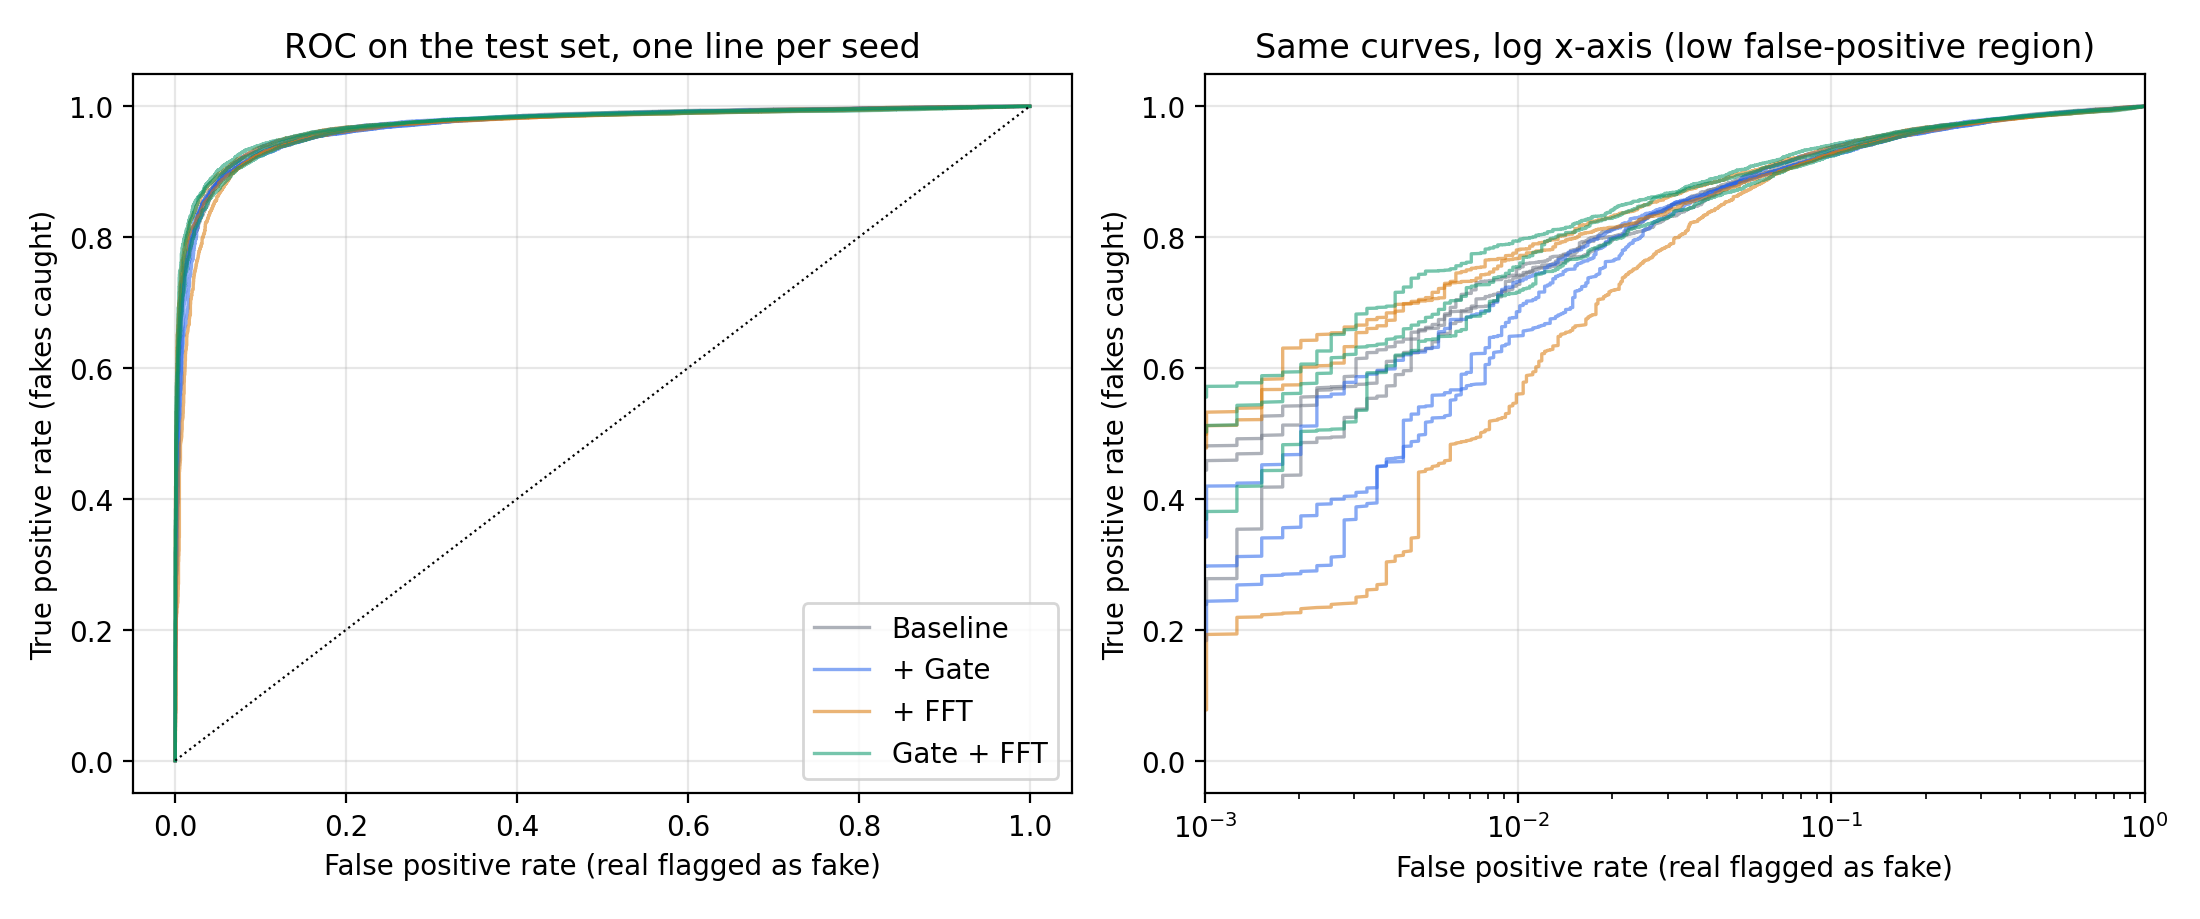

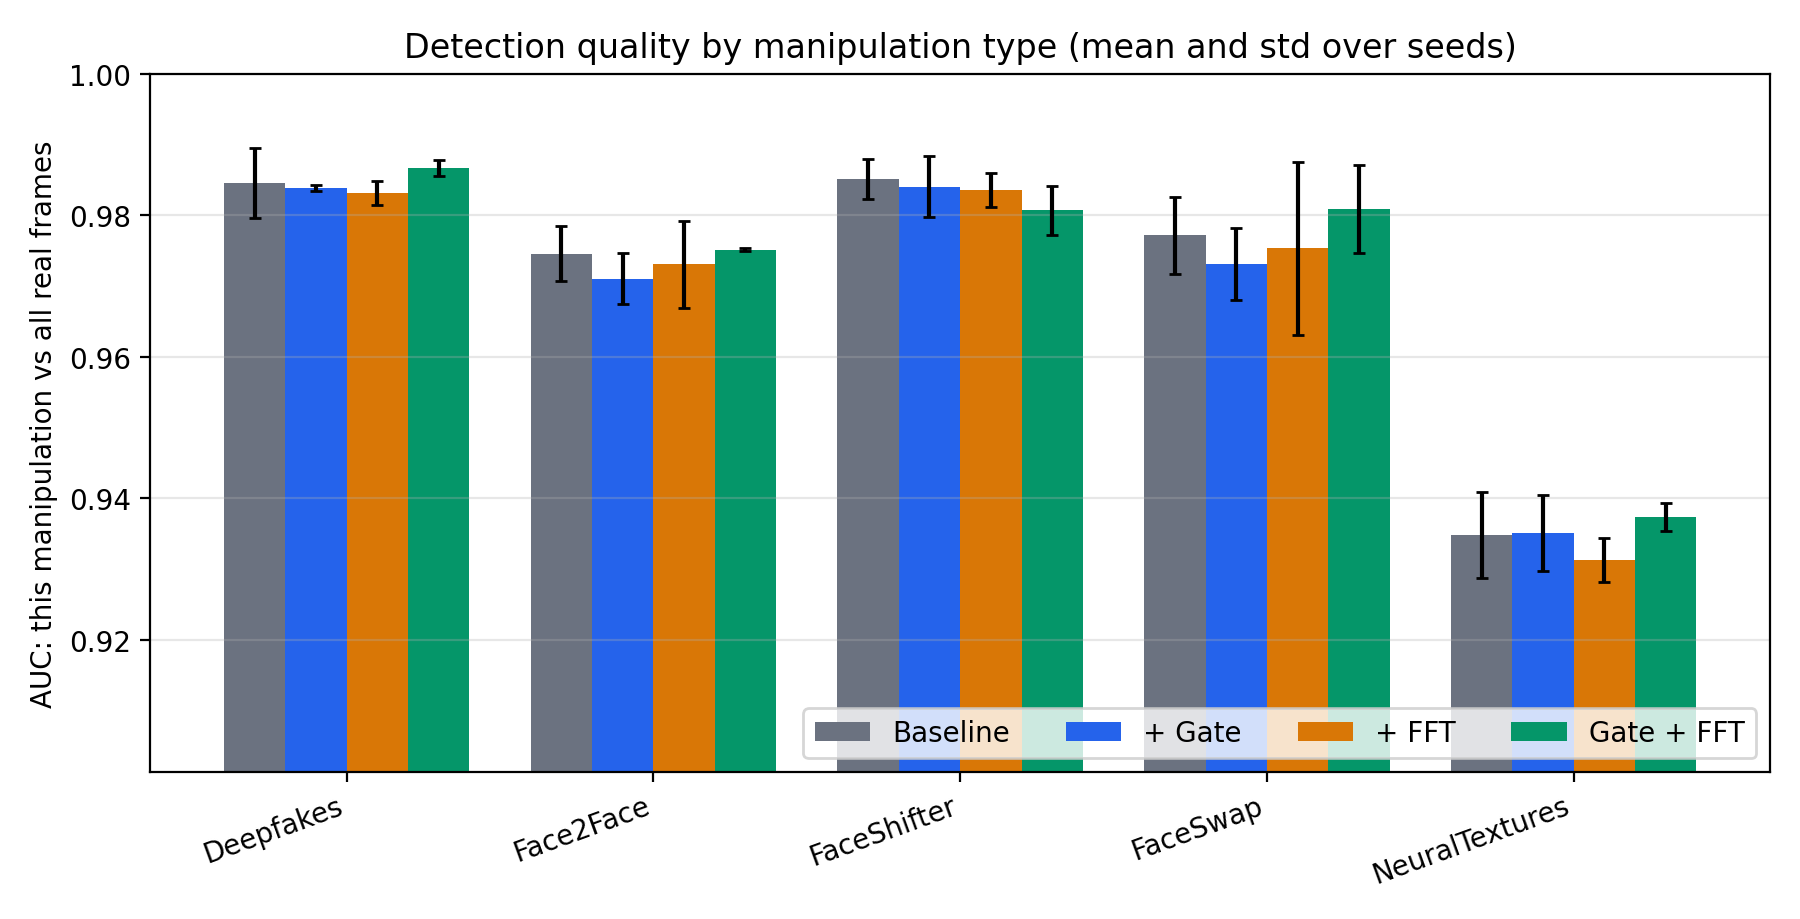

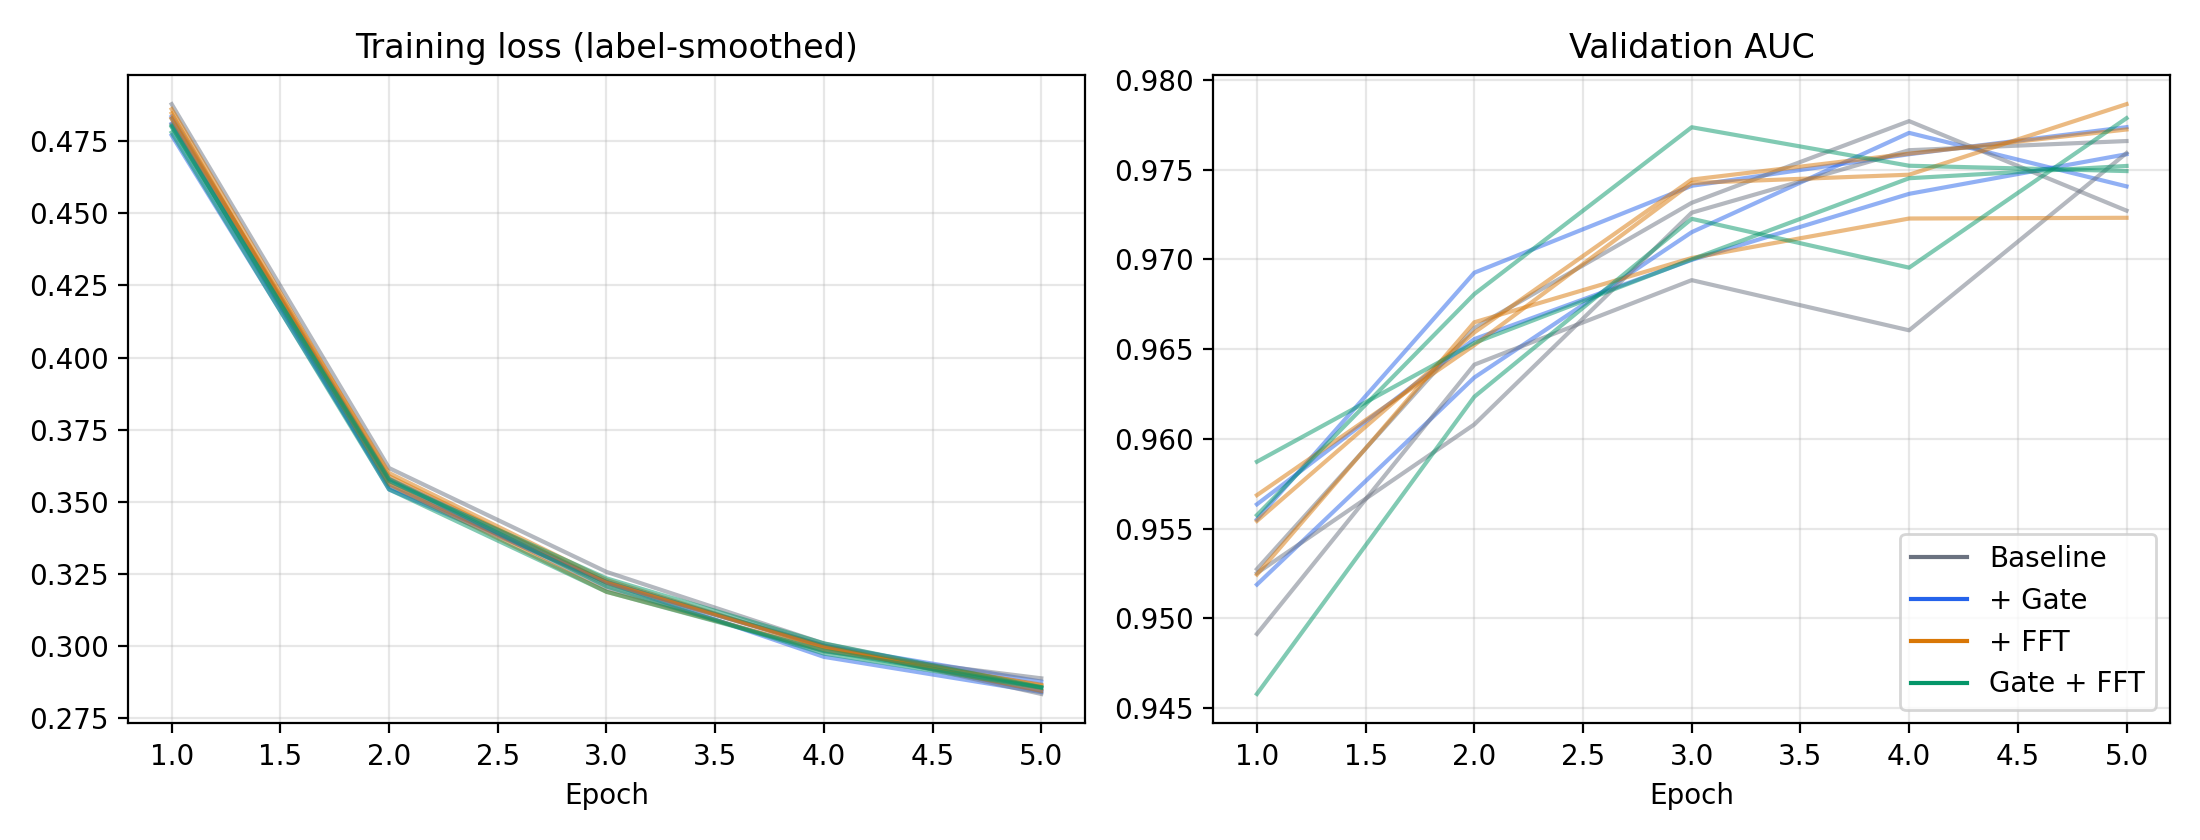

In [16]:
run("-m", "dfv2.report", "--runs-dir", OUT_DIR)

from IPython.display import Image, Markdown, display
report_dir = os.path.join(OUT_DIR, "report")
display(Markdown(open(os.path.join(report_dir, "report.md")).read()))
for name in ["roc_frame.png", "per_manipulation_auc.png", "learning_curves.png"]:
    display(Image(filename=os.path.join(report_dir, name)))

## How to read it

1. Start with **What the data supports**. Each line is a difference with a 95% interval; "not resolved" means the test set cannot tell the effect from zero. That is an honest result, not a failure.
2. **Component effects** separate the gate, the FFT branch and their interaction, using the same resampled videos on both sides.
3. **By manipulation type** shows whether a gain is spread across methods or comes from one.
4. Read the **caveats** before quoting any number.

When the runs with seeds 0, 1 and 2 are done, the results are ready to replace the old claims (93.34%, the Real-precision explanation) in the notebooks and the README.

Not covered here: other datasets, other compression levels, a redesigned frequency branch, and repeating the study over several split seeds (`--split-seed`).